In [ ]:
#Base imports
import ee
import csv
import pandas as pd
from google.colab import drive

#Mount GDrive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%%capture
!pip install osmnx scipy
!pip install rasterio geopandas contextily shapely pyproj fiona rtree h3 optuna

##Burden from emergent waste

Distance to waste

In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.mask import mask as rio_mask
from scipy.spatial import cKDTree

POP_DIR = "/content/drive/MyDrive/Paper_3/Data/Population"
SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"
SHAPE_DIR = "/content/drive/MyDrive/Results_2/City_shapefiles"

COUNTRY_ISO3 = {
    "Abidjan": "civ", "Accra": "gha", "Dakar": "sen", "Freetown": "sle",
    "Johannesburg": "zaf", "Kampala": "uga", "Kinshasa": "cod",
    "Lagos": "nga", "Maputo": "moz", "Nairobi": "ken"
}

CITIES = [
    "Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
    "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"
]

MIN_AREA_M2 = 500
MIN_RADIUS_M = 200
CAP_PERCENTILE = 99

def load_city_polygon(city):
    gdf = gpd.read_file(f"{SHAPE_DIR}/{city}_shape/{city}.shp")
    if len(gdf) > 1:
        gdf = gpd.GeoDataFrame(geometry=[gdf.unary_union], crs=gdf.crs)
    return gdf

def load_clipped_population(city, year):
    iso3 = COUNTRY_ISO3[city]
    path = f"{POP_DIR}/{year}/{city}/{iso3}_pop_{year}_CN_100m_R2025A_v1.tif"
    city_poly = load_city_polygon(city)

    with rasterio.open(path) as src:
        poly = city_poly.to_crs(src.crs)
        clipped, transform = rio_mask(src, poly.geometry, crop=True, nodata=src.nodata)
        nodata = src.nodata

    band = clipped[0]
    rows, cols = np.where(band != nodata)
    pop_values = band[rows, cols]
    xs, ys = rasterio.transform.xy(transform, rows, cols)

    return np.column_stack([xs, ys]), pop_values, city_poly

def load_sites(city, year, min_area_m2=MIN_AREA_M2):
    sites = pd.read_csv(f"{SITES_DIR}/{year}/{city}/{city}_{year}_sites.csv")
    sites = sites.dropna(subset=["latitude", "longitude", "area"])
    return sites[sites["area"] >= min_area_m2].copy()

# =====================================================================
# FIX: city-specific area caps, not one global cap across all cities
# =====================================================================

def calculate_city_area_caps(cities, percentile=99, min_area_m2=500):
    """Returns a dict {city: area_cap_m2}, each computed from ONLY that
    city's own qualifying sites, pooled across 2016+2024."""
    caps = {}
    for city in cities:
        areas = []
        for year in [2016, 2024]:
            sites = load_sites(city, year, min_area_m2)
            areas.extend(sites["area"].values)

        cap = np.percentile(areas, percentile)
        caps[city] = cap
        print(f"{city}: n={len(areas):,} sites, p{percentile}={cap:,.1f} m² ({cap/10000:.2f} ha)")

    return caps

def assign_site_radii(areas, area_cap, max_radius_m,
                      min_area_m2=500, min_radius_m=200):
    capped_area = np.minimum(np.asarray(areas), area_cap)
    score = (
        np.log(capped_area) - np.log(min_area_m2)
    ) / (
        np.log(area_cap) - np.log(min_area_m2)
    )
    return min_radius_m + (max_radius_m - min_radius_m) * score

def weighted_median(values, weights):
    order = np.argsort(values)
    values = values[order]
    weights = weights[order]
    return values[np.searchsorted(np.cumsum(weights), weights.sum() / 2)]

def compute_distance_metrics(city, year, max_radius_km, area_cap):
    centroids_lonlat, pop_values, city_poly = load_clipped_population(city, year)
    sites = load_sites(city, year)

    if len(sites) == 0:
        raise ValueError(f"No sites >= {MIN_AREA_M2} m²")

    utm_crs = city_poly.estimate_utm_crs()

    pixel_gdf = gpd.GeoDataFrame(
        {"pop": pop_values},
        geometry=gpd.points_from_xy(centroids_lonlat[:, 0], centroids_lonlat[:, 1]),
        crs="EPSG:4326"
    ).to_crs(utm_crs)

    site_gdf = gpd.GeoDataFrame(
        sites,
        geometry=gpd.points_from_xy(sites["longitude"], sites["latitude"]),
        crs="EPSG:4326"
    ).to_crs(utm_crs)

    pixel_coords = np.column_stack([pixel_gdf.geometry.x, pixel_gdf.geometry.y])
    site_coords = np.column_stack([site_gdf.geometry.x, site_gdf.geometry.y])

    site_radii = assign_site_radii(
        sites["area"].values,
        area_cap=area_cap,  # now the city's OWN cap, passed in by the caller
        max_radius_m=max_radius_km * 1000
    )

    tree = cKDTree(site_coords)
    nearest_dist, _ = tree.query(pixel_coords, k=1)

    candidate_sites = tree.query_ball_point(pixel_coords, r=max_radius_km * 1000)
    exposed = np.zeros(len(pixel_coords), dtype=bool)

    for i, candidates in enumerate(candidate_sites):
        if not candidates:
            continue
        candidates = np.asarray(candidates)
        distances = np.linalg.norm(site_coords[candidates] - pixel_coords[i], axis=1)
        if np.any(distances <= site_radii[candidates]):
            exposed[i] = True

    headcount_within = pop_values[exposed].sum()
    total_population = pop_values.sum()

    return {
        "year": year,
        "n_sites": len(sites),
        "total_population": float(total_population),
        "headcount_exposed": float(headcount_within),
        "pct_population_exposed": float(headcount_within / total_population * 100),
        "avg_distance_by_area_m": float(nearest_dist.mean()),
        "typical_distance_by_area_m": float(np.median(nearest_dist)),
        "typical_distance_by_resident_m": float(weighted_median(nearest_dist, pop_values)),
        "mean_site_radius_m": float(site_radii.mean()),
        "median_site_radius_m": float(np.median(site_radii)),
        "max_site_radius_m": float(site_radii.max())
    }

def compute_all_cities(cities, max_radius_km, area_caps):
    """area_caps: dict {city: area_cap_m2} — looks up each city's OWN cap."""
    results = []
    for city in cities:
        for year in [2016, 2024]:
            try:
                metrics = compute_distance_metrics(
                    city, year,
                    max_radius_km=max_radius_km,
                    area_cap=area_caps[city]
                )
                metrics["city"] = city
                results.append(metrics)
                print(f"{city} {year}: done")
            except Exception as e:
                print(f"WARNING: {city} {year} failed — {e}")

    return pd.DataFrame(results)

def create_summary_table(results_df, cities, max_radius_km):
    rows = []
    for city in cities:
        sub = results_df[results_df["city"] == city].set_index("year")
        if 2016 not in sub.index or 2024 not in sub.index:
            continue

        row = {
            "city": city,
            "n_sites_2016": sub.loc[2016, "n_sites"],
            "n_sites_2024": sub.loc[2024, "n_sites"],
            "total_population_2016": sub.loc[2016, "total_population"],
            "total_population_2024": sub.loc[2024, "total_population"],
            "headcount_exposed_2016": sub.loc[2016, "headcount_exposed"],
            "headcount_exposed_2024": sub.loc[2024, "headcount_exposed"],
            "headcount_diff": sub.loc[2024, "headcount_exposed"] - sub.loc[2016, "headcount_exposed"],
            "pct_population_exposed_2016": sub.loc[2016, "pct_population_exposed"],
            "pct_population_exposed_2024": sub.loc[2024, "pct_population_exposed"],
            "avg_distance_by_area_m_2016": sub.loc[2016, "avg_distance_by_area_m"],
            "avg_distance_by_area_m_2024": sub.loc[2024, "avg_distance_by_area_m"],
            "typical_distance_by_area_m_2016": sub.loc[2016, "typical_distance_by_area_m"],
            "typical_distance_by_area_m_2024": sub.loc[2024, "typical_distance_by_area_m"],
            "typical_distance_by_resident_m_2016": sub.loc[2016, "typical_distance_by_resident_m"],
            "typical_distance_by_resident_m_2024": sub.loc[2024, "typical_distance_by_resident_m"],
            "median_radius_m_2016": sub.loc[2016, "median_site_radius_m"],
            "median_radius_m_2024": sub.loc[2024, "median_site_radius_m"]
        }
        rows.append(row)

    return pd.DataFrame(rows).set_index("city").round(1)

# =====================================================================
# Main
# =====================================================================

AREA_CAPS = calculate_city_area_caps(CITIES, percentile=CAP_PERCENTILE, min_area_m2=MIN_AREA_M2)

results_2km = compute_all_cities(CITIES, max_radius_km=2, area_caps=AREA_CAPS)
summary_2km = create_summary_table(results_2km, CITIES, max_radius_km=2)
print("\nVARIABLE-RADIUS EXPOSURE — MAXIMUM 2 KM")
print(f"500 m² = 200 m; each city's own p{CAP_PERCENTILE} area = 2 km")
print(summary_2km.to_string())

results_5km = compute_all_cities(CITIES, max_radius_km=5, area_caps=AREA_CAPS)
summary_5km = create_summary_table(results_5km, CITIES, max_radius_km=5)
print("\nVARIABLE-RADIUS EXPOSURE — MAXIMUM 5 KM")
print(f"500 m² = 200 m; each city's own p{CAP_PERCENTILE} area = 5 km")
print(summary_5km.to_string())

Abidjan: n=155 sites, p99=33,786.6 m² (3.38 ha)
Accra: n=348 sites, p99=68,549.0 m² (6.85 ha)
Dakar: n=75 sites, p99=71,046.5 m² (7.10 ha)
Freetown: n=80 sites, p99=24,997.7 m² (2.50 ha)
Johannesburg: n=692 sites, p99=66,575.5 m² (6.66 ha)
Kampala: n=140 sites, p99=54,315.5 m² (5.43 ha)
Kinshasa: n=164 sites, p99=5,221.3 m² (0.52 ha)
Lagos: n=800 sites, p99=29,579.4 m² (2.96 ha)
Maputo: n=85 sites, p99=172,163.5 m² (17.22 ha)
Nairobi: n=134 sites, p99=178,318.1 m² (17.83 ha)
Abidjan 2016: done
Abidjan 2024: done
Accra 2016: done
Accra 2024: done
Dakar 2016: done
Dakar 2024: done
Freetown 2016: done
Freetown 2024: done
Johannesburg 2016: done
Johannesburg 2024: done
Kampala 2016: done
Kampala 2024: done
Kinshasa 2016: done
Kinshasa 2024: done
Lagos 2016: done
Lagos 2024: done
Maputo 2016: done
Maputo 2024: done
Nairobi 2016: done
Nairobi 2024: done

VARIABLE-RADIUS EXPOSURE — MAXIMUM 2 KM
500 m² = 200 m; each city's own p99 area = 2 km
              n_sites_2016  n_sites_2024  total_pop

Future Projections

In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.mask import mask as rio_mask
from scipy.spatial import cKDTree

POP_FUTURE_DIR = "/content/drive/MyDrive/Paper_3/Data/Population/Future_predictions"
SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"
SHAPE_DIR = "/content/drive/MyDrive/Results_2/City_shapefiles"

COUNTRY_ISO3 = {
    "Abidjan": "civ", "Accra": "gha", "Dakar": "sen", "Freetown": "sle",
    "Johannesburg": "zaf", "Kampala": "uga", "Kinshasa": "cod",
    "Lagos": "nga", "Maputo": "moz", "Nairobi": "ken"
}

CITIES = [
    "Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
    "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"
]

FUTURE_YEARS = [2026, 2028, 2030]
MIN_AREA_M2 = 500
MIN_RADIUS_M = 200
MAX_RADIUS_KM = 2
CAP_PERCENTILE = 99

def load_city_polygon(city):
    gdf = gpd.read_file(f"{SHAPE_DIR}/{city}_shape/{city}.shp")
    if len(gdf) > 1:
        gdf = gpd.GeoDataFrame(geometry=[gdf.unary_union], crs=gdf.crs)
    return gdf

def load_sites_2024(city, min_area_m2=MIN_AREA_M2):
    sites = pd.read_csv(f"{SITES_DIR}/2024/{city}/{city}_2024_sites.csv")
    sites = sites.dropna(subset=["latitude", "longitude", "area"])
    return sites[sites["area"] >= min_area_m2].copy()

def calculate_2024_area_caps(cities, percentile=CAP_PERCENTILE, min_area_m2=MIN_AREA_M2):
    """Area cap computed from EACH city's own 2024 sites only (not pooled with 2016)."""
    caps = {}
    for city in cities:
        sites = load_sites_2024(city, min_area_m2)
        cap = np.percentile(sites["area"].values, percentile)
        caps[city] = cap
        print(f"{city}: n={len(sites):,} 2024 sites >= {min_area_m2}m², "
              f"p{percentile}={cap:,.1f} m² ({cap/10000:.2f} ha)")
    return caps

def assign_site_radii(areas, area_cap, max_radius_m, min_area_m2=MIN_AREA_M2, min_radius_m=MIN_RADIUS_M):
    capped_area = np.minimum(np.asarray(areas), area_cap)
    score = (np.log(capped_area) - np.log(min_area_m2)) / (np.log(area_cap) - np.log(min_area_m2))
    return min_radius_m + (max_radius_m - min_radius_m) * score

def weighted_median(values, weights):
    order = np.argsort(values)
    values = values[order]
    weights = weights[order]
    return values[np.searchsorted(np.cumsum(weights), weights.sum() / 2)]

def load_clipped_population_future(city, year):
    iso3 = COUNTRY_ISO3[city]
    path = f"{POP_FUTURE_DIR}/{city}/{iso3}_pop_{year}_CN_100m_R2025A_v1.tif"
    city_poly = load_city_polygon(city)

    with rasterio.open(path) as src:
        poly = city_poly.to_crs(src.crs)
        clipped, transform = rio_mask(src, poly.geometry, crop=True, nodata=src.nodata)
        nodata = src.nodata

    band = clipped[0]
    rows, cols = np.where(band != nodata)
    pop_values = band[rows, cols]
    xs, ys = rasterio.transform.xy(transform, rows, cols)

    return np.column_stack([xs, ys]), pop_values, city_poly

def compute_future_exposure(city, year, area_cap, sites_2024, city_poly, max_radius_km=MAX_RADIUS_KM):
    centroids_lonlat, pop_values, _ = load_clipped_population_future(city, year)

    utm_crs = city_poly.estimate_utm_crs()

    pixel_gdf = gpd.GeoDataFrame(
        {"pop": pop_values},
        geometry=gpd.points_from_xy(centroids_lonlat[:, 0], centroids_lonlat[:, 1]),
        crs="EPSG:4326"
    ).to_crs(utm_crs)

    site_gdf = gpd.GeoDataFrame(
        sites_2024,
        geometry=gpd.points_from_xy(sites_2024["longitude"], sites_2024["latitude"]),
        crs="EPSG:4326"
    ).to_crs(utm_crs)

    pixel_coords = np.column_stack([pixel_gdf.geometry.x, pixel_gdf.geometry.y])
    site_coords = np.column_stack([site_gdf.geometry.x, site_gdf.geometry.y])

    site_radii = assign_site_radii(
        sites_2024["area"].values, area_cap=area_cap, max_radius_m=max_radius_km * 1000
    )

    tree = cKDTree(site_coords)
    candidate_sites = tree.query_ball_point(pixel_coords, r=max_radius_km * 1000)
    exposed = np.zeros(len(pixel_coords), dtype=bool)

    for i, candidates in enumerate(candidate_sites):
        if not candidates:
            continue
        candidates = np.asarray(candidates)
        distances = np.linalg.norm(site_coords[candidates] - pixel_coords[i], axis=1)
        if np.any(distances <= site_radii[candidates]):
            exposed[i] = True

    headcount_within = pop_values[exposed].sum()
    total_population = pop_values.sum()

    return {
        "city": city,
        "year": year,
        "n_sites_2024": len(sites_2024),
        "area_cap_2024_m2": area_cap,
        "total_population": float(total_population),
        "headcount_exposed": float(headcount_within),
        "pct_population_exposed": float(headcount_within / total_population * 100),
    }

# =====================================================================
# Main
# =====================================================================

# print("Computing 2024-only area caps (per city)...")
# AREA_CAPS_2024 = calculate_2024_area_caps(CITIES)

results = []
for city in CITIES:
    sites_2024 = load_sites_2024(city)
    city_poly = load_city_polygon(city)

    for year in FUTURE_YEARS:
        try:
            row = compute_future_exposure(
                city, year,
                area_cap=AREA_CAPS[city],
                sites_2024=sites_2024,
                city_poly=city_poly,
            )
            results.append(row)
            print(f"{city} {year}: {row['pct_population_exposed']:.2f}% "
                  f"({row['headcount_exposed']:,.0f} / {row['total_population']:,.0f})")
        except Exception as e:
            print(f"WARNING: {city} {year} failed — {e}")

results_df = pd.DataFrame(results)

# --- summary table: one row per city, one column set per year ---
summary = results_df.pivot(index="city", columns="year",
                            values=["total_population", "headcount_exposed", "pct_population_exposed"])
summary.columns = [f"{metric}_{year}" for metric, year in summary.columns]
summary = summary.round(2)

print("\n" + "=" * 70)
print("FUTURE POPULATION EXPOSURE — 2024 SITE GEOMETRY, 2026/2028/2030 POPULATION")
print(f"Area cap computed from 2024 sites only, per city. Max radius = {MAX_RADIUS_KM}km.")
print("=" * 70)
print(summary.to_string())

out_path = "/content/drive/MyDrive/Paper_3/Processing/DV/Revised/future_population_exposure_2024sites.csv"
summary.to_csv(out_path)
print(f"\nSaved: {out_path}")

Computing 2024-only area caps (per city)...
Abidjan: n=92 2024 sites >= 500m², p99=23,632.6 m² (2.36 ha)
Accra: n=209 2024 sites >= 500m², p99=60,174.7 m² (6.02 ha)
Dakar: n=39 2024 sites >= 500m², p99=53,495.0 m² (5.35 ha)
Freetown: n=47 2024 sites >= 500m², p99=32,279.8 m² (3.23 ha)
Johannesburg: n=488 2024 sites >= 500m², p99=90,494.4 m² (9.05 ha)
Kampala: n=94 2024 sites >= 500m², p99=11,628.8 m² (1.16 ha)
Kinshasa: n=88 2024 sites >= 500m², p99=5,870.6 m² (0.59 ha)
Lagos: n=472 2024 sites >= 500m², p99=32,657.1 m² (3.27 ha)
Maputo: n=45 2024 sites >= 500m², p99=143,720.4 m² (14.37 ha)
Nairobi: n=72 2024 sites >= 500m², p99=119,847.0 m² (11.98 ha)
Abidjan 2026: 15.48% (1,094,514 / 7,072,174)
Abidjan 2028: 15.48% (1,146,926 / 7,407,389)
Abidjan 2030: 15.49% (1,200,918 / 7,750,615)
Accra 2026: 13.62% (853,132 / 6,263,752)
Accra 2028: 13.62% (883,412 / 6,486,428)
Accra 2030: 13.62% (913,707 / 6,708,758)
Dakar 2026: 8.26% (318,867 / 3,862,285)
Dakar 2028: 8.28% (330,984 / 3,999,304)
Da

Computing pooled (2016+2024) area caps...
Abidjan 2016: 15.85% (867,303 / 5,473,263)
Abidjan 2024: 13.95% (940,409 / 6,740,675)
Accra 2016: 14.16% (727,832 / 5,140,725)
Accra 2024: 13.17% (795,532 / 6,039,145)
Dakar 2016: 12.34% (396,743 / 3,214,912)
Dakar 2024: 7.62% (284,314 / 3,730,203)
Freetown 2016: 16.70% (179,453 / 1,074,808)
Freetown 2024: 29.91% (356,093 / 1,190,422)
Johannesburg 2016: 4.41% (426,662 / 9,672,661)
Johannesburg 2024: 8.99% (963,363 / 10,710,747)
Kampala 2016: 8.74% (303,689 / 3,475,660)
Kampala 2024: 11.32% (507,318 / 4,483,456)
Kinshasa 2016: 29.98% (1,617,166 / 5,394,124)
Kinshasa 2024: 40.58% (2,863,790 / 7,056,358)
Lagos 2016: 26.48% (3,452,704 / 13,036,738)
Lagos 2024: 35.20% (5,452,072 / 15,489,241)
Maputo 2016: 11.41% (214,948 / 1,884,447)
Maputo 2024: 14.28% (337,934 / 2,366,911)
Nairobi 2016: 18.24% (801,527 / 4,394,910)
Nairobi 2024: 24.62% (1,262,051 / 5,125,960)

Computing 2024-only area caps...
Abidjan 2026: 15.48% (1,094,514 / 7,072,174)
Abidjan 20

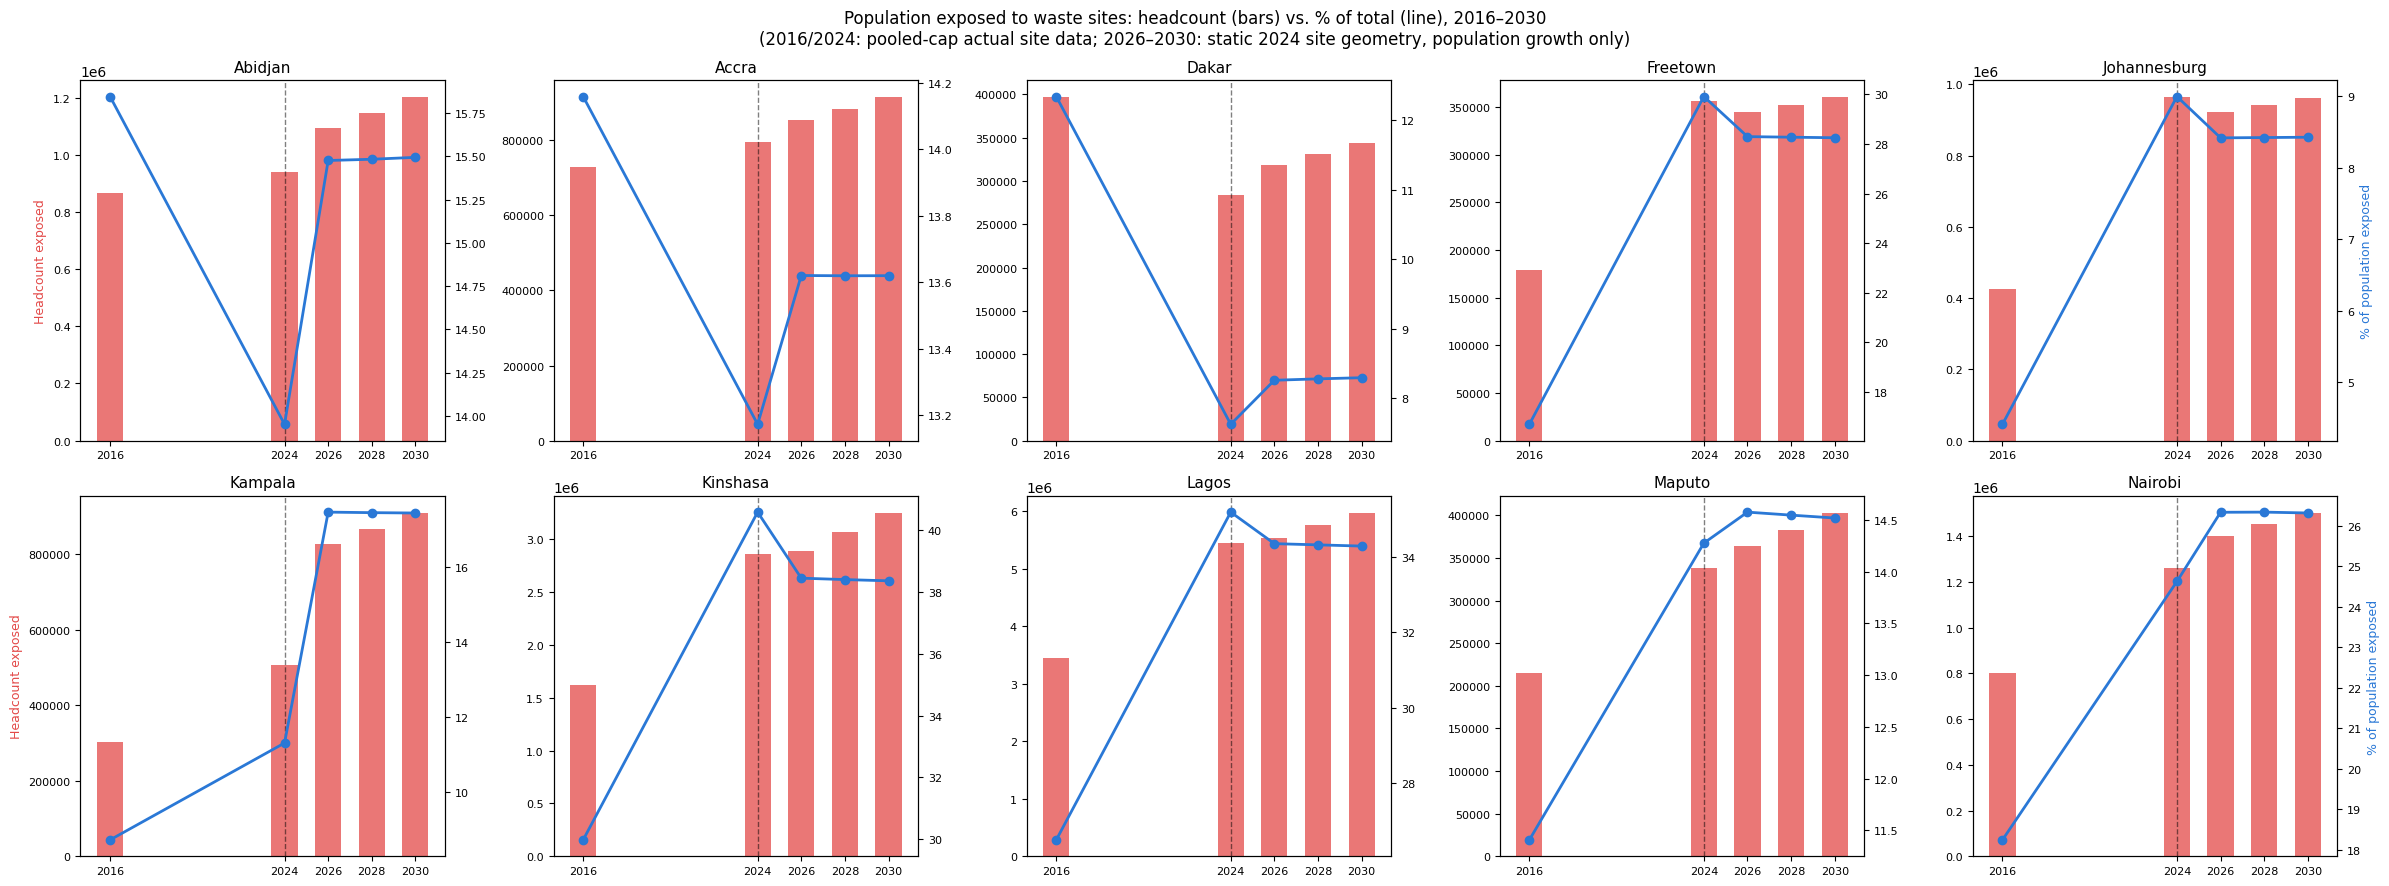

In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.mask import mask as rio_mask
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt

POP_DIR = "/content/drive/MyDrive/Paper_3/Data/Population"
POP_FUTURE_DIR = "/content/drive/MyDrive/Paper_3/Data/Population/Future_predictions"
SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"
SHAPE_DIR = "/content/drive/MyDrive/Results_2/City_shapefiles"

COUNTRY_ISO3 = {
    "Abidjan": "civ", "Accra": "gha", "Dakar": "sen", "Freetown": "sle",
    "Johannesburg": "zaf", "Kampala": "uga", "Kinshasa": "cod",
    "Lagos": "nga", "Maputo": "moz", "Nairobi": "ken"
}
CITIES = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
          "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

MIN_AREA_M2 = 500
MIN_RADIUS_M = 200
MAX_RADIUS_KM = 2
CAP_PERCENTILE = 99
FUTURE_YEARS = [2026, 2028, 2030]

# =====================================================================
# Shared helpers
# =====================================================================

def load_city_polygon(city):
    gdf = gpd.read_file(f"{SHAPE_DIR}/{city}_shape/{city}.shp")
    if len(gdf) > 1:
        gdf = gpd.GeoDataFrame(geometry=[gdf.unary_union], crs=gdf.crs)
    return gdf

def load_sites(city, year, min_area_m2=MIN_AREA_M2):
    sites = pd.read_csv(f"{SITES_DIR}/{year}/{city}/{city}_{year}_sites.csv")
    sites = sites.dropna(subset=["latitude", "longitude", "area"])
    return sites[sites["area"] >= min_area_m2].copy()

def assign_site_radii(areas, area_cap, max_radius_m, min_area_m2=MIN_AREA_M2, min_radius_m=MIN_RADIUS_M):
    capped_area = np.minimum(np.asarray(areas), area_cap)
    score = (np.log(capped_area) - np.log(min_area_m2)) / (np.log(area_cap) - np.log(min_area_m2))
    return min_radius_m + (max_radius_m - min_radius_m) * score

def compute_exposure_generic(pop_points_lonlat, pop_values, city_poly, sites, area_cap, max_radius_km=MAX_RADIUS_KM):
    utm_crs = city_poly.estimate_utm_crs()

    pixel_gdf = gpd.GeoDataFrame(
        {"pop": pop_values},
        geometry=gpd.points_from_xy(pop_points_lonlat[:, 0], pop_points_lonlat[:, 1]),
        crs="EPSG:4326"
    ).to_crs(utm_crs)

    site_gdf = gpd.GeoDataFrame(
        sites, geometry=gpd.points_from_xy(sites["longitude"], sites["latitude"]), crs="EPSG:4326"
    ).to_crs(utm_crs)

    pixel_coords = np.column_stack([pixel_gdf.geometry.x, pixel_gdf.geometry.y])
    site_coords = np.column_stack([site_gdf.geometry.x, site_gdf.geometry.y])

    site_radii = assign_site_radii(sites["area"].values, area_cap=area_cap, max_radius_m=max_radius_km * 1000)

    tree = cKDTree(site_coords)
    candidate_sites = tree.query_ball_point(pixel_coords, r=max_radius_km * 1000)
    exposed = np.zeros(len(pixel_coords), dtype=bool)

    for i, candidates in enumerate(candidate_sites):
        if not candidates:
            continue
        candidates = np.asarray(candidates)
        distances = np.linalg.norm(site_coords[candidates] - pixel_coords[i], axis=1)
        if np.any(distances <= site_radii[candidates]):
            exposed[i] = True

    headcount = pop_values[exposed].sum()
    total = pop_values.sum()
    return float(headcount), float(total)

# =====================================================================
# PAST (2016 / 2024) — pooled area cap, matching the locked design
# =====================================================================

def load_clipped_population(city, year):
    iso3 = COUNTRY_ISO3[city]
    path = f"{POP_DIR}/{year}/{city}/{iso3}_pop_{year}_CN_100m_R2025A_v1.tif"
    city_poly = load_city_polygon(city)
    with rasterio.open(path) as src:
        poly = city_poly.to_crs(src.crs)
        clipped, transform = rio_mask(src, poly.geometry, crop=True, nodata=src.nodata)
        nodata = src.nodata
    band = clipped[0]
    rows, cols = np.where(band != nodata)
    pop_values = band[rows, cols]
    xs, ys = rasterio.transform.xy(transform, rows, cols)
    return np.column_stack([xs, ys]), pop_values, city_poly

print("Computing pooled (2016+2024) area caps...")
pooled_caps = {}
for city in CITIES:
    areas = []
    for year in [2016, 2024]:
        areas.extend(load_sites(city, year)["area"].values)
    pooled_caps[city] = np.percentile(areas, CAP_PERCENTILE)

past_rows = []
for city in CITIES:
    city_poly = load_city_polygon(city)
    for year in [2016, 2024]:
        sites = load_sites(city, year)
        pop_coords, pop_values, _ = load_clipped_population(city, year)
        headcount, total = compute_exposure_generic(pop_coords, pop_values, city_poly, sites, pooled_caps[city])
        past_rows.append({
            "city": city, "year": year,
            "total_population": total, "headcount_exposed": headcount,
            "pct_population_exposed": 100 * headcount / total,
        })
        print(f"{city} {year}: {100*headcount/total:.2f}% ({headcount:,.0f} / {total:,.0f})")

past_df = pd.DataFrame(past_rows)

# =====================================================================
# FUTURE (2026 / 2028 / 2030) — 2024-only area cap, static 2024 sites
# =====================================================================

def load_clipped_population_future(city, year):
    iso3 = COUNTRY_ISO3[city]
    path = f"{POP_FUTURE_DIR}/{city}/{iso3}_pop_{year}_CN_100m_R2025A_v1.tif"
    city_poly = load_city_polygon(city)
    with rasterio.open(path) as src:
        poly = city_poly.to_crs(src.crs)
        clipped, transform = rio_mask(src, poly.geometry, crop=True, nodata=src.nodata)
        nodata = src.nodata
    band = clipped[0]
    rows, cols = np.where(band != nodata)
    pop_values = band[rows, cols]
    xs, ys = rasterio.transform.xy(transform, rows, cols)
    return np.column_stack([xs, ys]), pop_values, city_poly

print("\nComputing 2024-only area caps...")
caps_2024 = {city: np.percentile(load_sites(city, 2024)["area"].values, CAP_PERCENTILE) for city in CITIES}

future_rows = []
for city in CITIES:
    sites_2024 = load_sites(city, 2024)
    city_poly = load_city_polygon(city)
    for year in FUTURE_YEARS:
        pop_coords, pop_values, _ = load_clipped_population_future(city, year)
        headcount, total = compute_exposure_generic(pop_coords, pop_values, city_poly, sites_2024, caps_2024[city])
        future_rows.append({
            "city": city, "year": year,
            "total_population": total, "headcount_exposed": headcount,
            "pct_population_exposed": 100 * headcount / total,
        })
        print(f"{city} {year}: {100*headcount/total:.2f}% ({headcount:,.0f} / {total:,.0f})")

future_df = pd.DataFrame(future_rows)

# =====================================================================
# Chart — dual axis, headcount (bars) + % exposed (line), per city
# =====================================================================

fig, axes = plt.subplots(2, 5, figsize=(24, 9))
axes = axes.flatten()

for i, city in enumerate(CITIES):
    ax1 = axes[i]
    ax2 = ax1.twinx()

    years = [2016, 2024] + FUTURE_YEARS
    hc = (past_df.loc[past_df.city == city].set_index("year")["headcount_exposed"].reindex([2016, 2024]).tolist()
          + future_df.loc[future_df.city == city].set_index("year")["headcount_exposed"].reindex(FUTURE_YEARS).tolist())
    pct = (past_df.loc[past_df.city == city].set_index("year")["pct_population_exposed"].reindex([2016, 2024]).tolist()
           + future_df.loc[future_df.city == city].set_index("year")["pct_population_exposed"].reindex(FUTURE_YEARS).tolist())

    ax1.bar(years, hc, width=1.2, color="#e34948", alpha=0.75)
    ax2.plot(years, pct, color="#2a78d6", marker="o", linewidth=2)
    ax1.axvline(2024, color="black", linewidth=1, linestyle="--", alpha=0.5)

    ax1.set_title(city, fontsize=11)
    ax1.set_xticks(years)
    ax1.tick_params(labelsize=8)
    ax2.tick_params(labelsize=8)
    if i % 5 == 0:
        ax1.set_ylabel("Headcount exposed", fontsize=9, color="#e34948")
    if i % 5 == 4:
        ax2.set_ylabel("% of population exposed", fontsize=9, color="#2a78d6")

fig.suptitle("Population exposed to waste sites: headcount (bars) vs. % of total (line), 2016–2030\n"
             "(2016/2024: pooled-cap actual site data; 2026–2030: static 2024 site geometry, population growth only)",
             fontsize=12)
plt.tight_layout()
plt.show()

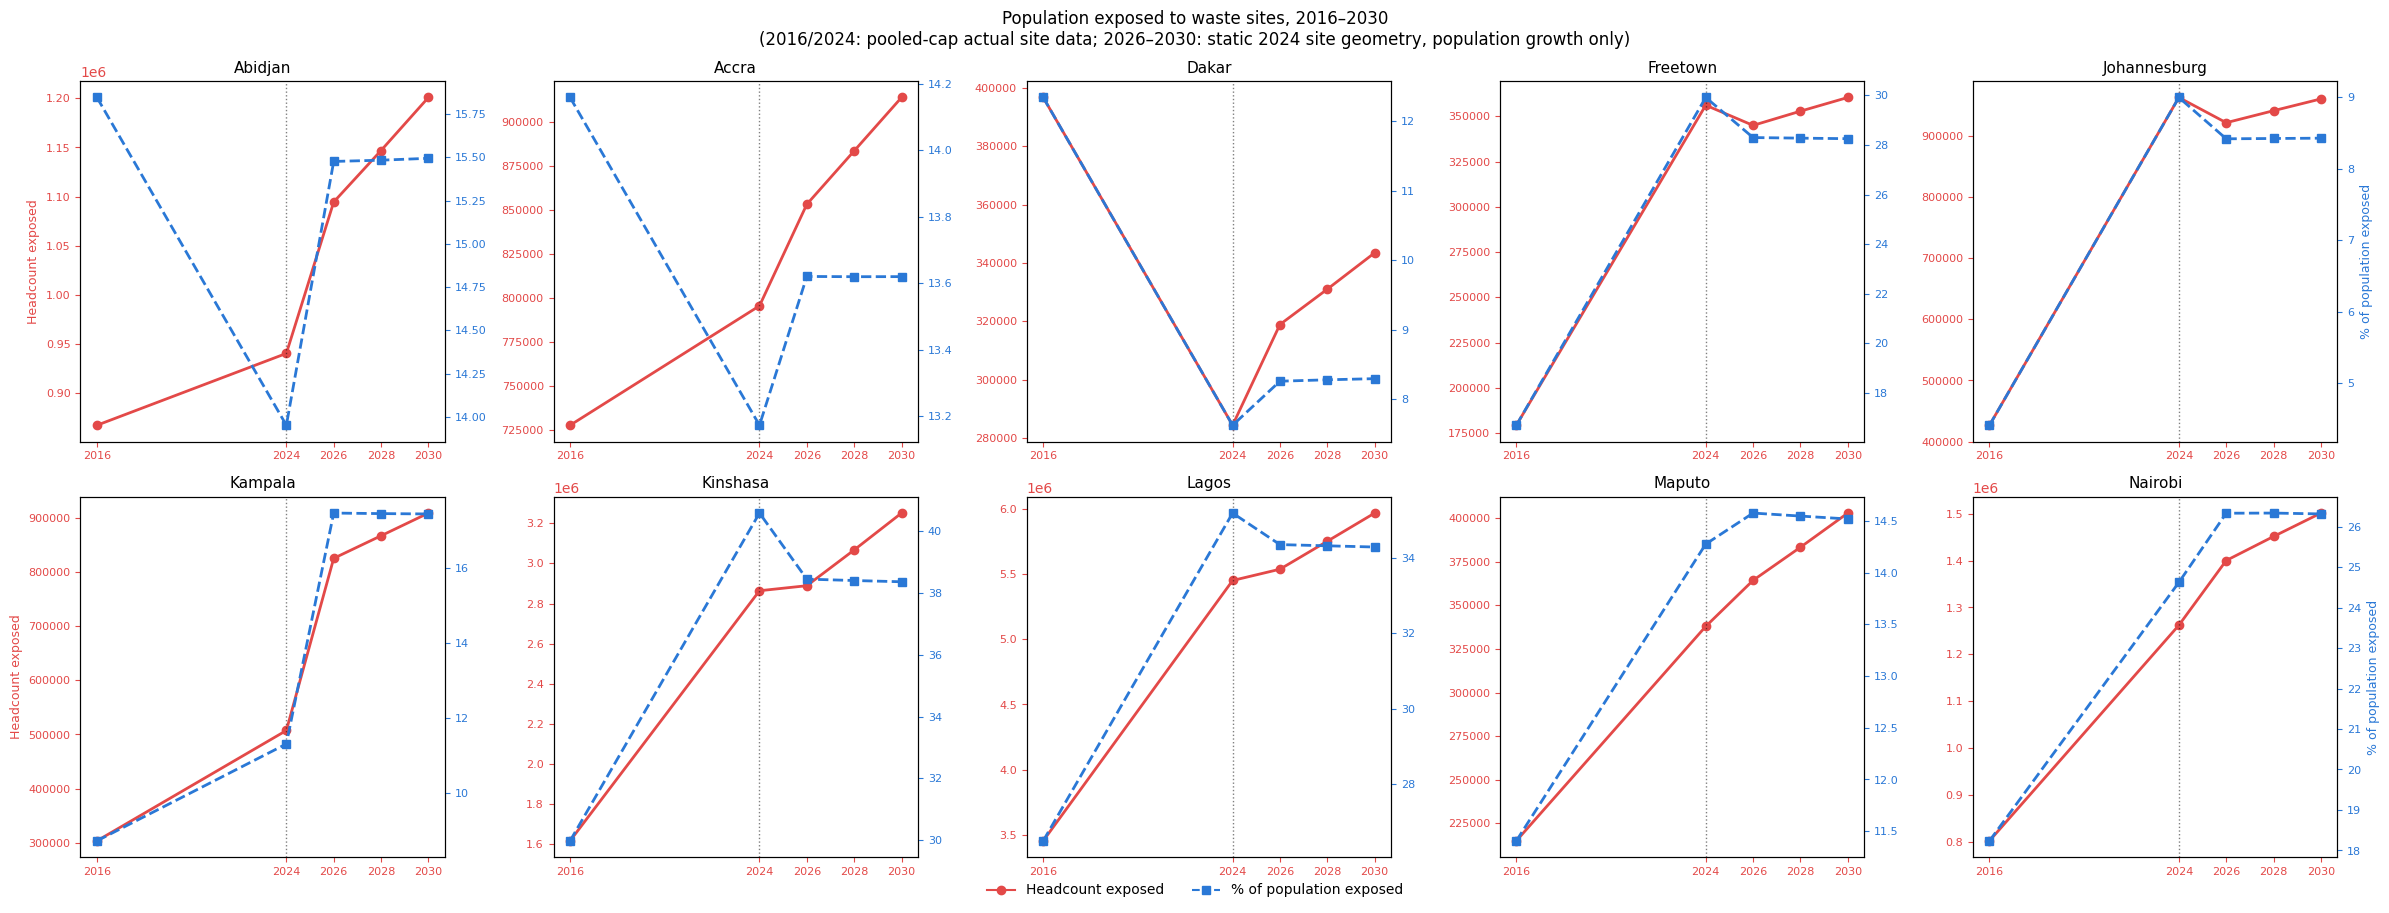

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(24, 9))
axes = axes.flatten()

for i, city in enumerate(CITIES):
    ax1 = axes[i]
    ax2 = ax1.twinx()

    years = [2016, 2024] + FUTURE_YEARS
    hc = (past_df.loc[past_df.city == city].set_index("year")["headcount_exposed"].reindex([2016, 2024]).tolist()
          + future_df.loc[future_df.city == city].set_index("year")["headcount_exposed"].reindex(FUTURE_YEARS).tolist())
    pct = (past_df.loc[past_df.city == city].set_index("year")["pct_population_exposed"].reindex([2016, 2024]).tolist()
           + future_df.loc[future_df.city == city].set_index("year")["pct_population_exposed"].reindex(FUTURE_YEARS).tolist())

    ax1.plot(years, hc, color="#e34948", marker="o", linewidth=2, label="Headcount exposed")
    ax2.plot(years, pct, color="#2a78d6", marker="s", linewidth=2, linestyle="--", label="% of population exposed")
    ax1.axvline(2024, color="black", linewidth=1, linestyle=":", alpha=0.5)

    ax1.set_title(city, fontsize=11)
    ax1.set_xticks(years)
    ax1.tick_params(labelsize=8, colors="#e34948")
    ax2.tick_params(labelsize=8, colors="#2a78d6")
    if i % 5 == 0:
        ax1.set_ylabel("Headcount exposed", fontsize=9, color="#e34948")
    if i % 5 == 4:
        ax2.set_ylabel("% of population exposed", fontsize=9, color="#2a78d6")

handles = [plt.Line2D([], [], color="#e34948", marker="o", label="Headcount exposed"),
           plt.Line2D([], [], color="#2a78d6", marker="s", linestyle="--", label="% of population exposed")]
fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.02))

fig.suptitle("Population exposed to waste sites, 2016–2030\n"
             "(2016/2024: pooled-cap actual site data; 2026–2030: static 2024 site geometry, population growth only)",
             fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go

SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"
YEARS = [2016, 2024]

cities = [
    "Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
    "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"
]

categories = [
    "Micro-sites (<100 m²)",
    "Neighbourhood waste (100–1,000 m²)",
    "Intermediate sites (1,000–10,000 m²)",
    "Landfills (≥10,000 m²)"
]

city_colors = [
    "#7f1d1d", "#a33a3a", "#c55245", "#df704b", "#e89155",
    "#e7b95f", "#d9cf72", "#b9c98a", "#91b89b", "#6e9f9a"
]

category_colors = [
    "#a51c30",
    "#df6b32",
    "#f2df62",
    "#c9d8a5"
]

def classify_site(area):
    if area < 100:
        return categories[0]
    elif area < 1000:
        return categories[1]
    elif area < 10000:
        return categories[2]
    return categories[3]

def make_sankey(year):
    frames = []

    for city in cities:
        path = f"{SITES_DIR}/{year}/{city}/{city}_{year}_sites.csv"
        df = pd.read_csv(path)
        df = df.dropna(subset=["area"]).copy()
        df["city"] = city
        df["category"] = df["area"].apply(classify_site)
        frames.append(df)

    all_sites = pd.concat(frames, ignore_index=True)

    count_table = (
        all_sites.groupby(["city", "category"])
        .size()
        .unstack(fill_value=0)
        .reindex(index=cities, columns=categories, fill_value=0)
    )

    pct_table = count_table.div(count_table.sum(axis=1), axis=0) * 100

    print(f"\nSITE COUNTS BY CATEGORY — {year}")
    print(count_table.to_string())

    print(f"\nPERCENTAGE OF EACH CITY'S SITES — {year}")
    print(pct_table.round(1).to_string())

    labels = cities + categories
    node_colors = city_colors + category_colors

    source = []
    target = []
    value = []
    link_colors = []

    for i, city in enumerate(cities):
        for j, category in enumerate(categories):
            n = int(count_table.loc[city, category])

            if n > 0:
                source.append(i)
                target.append(len(cities) + j)
                value.append(n)

                hex_col = city_colors[i].lstrip("#")
                rgb = tuple(int(hex_col[k:k+2], 16) for k in (0, 2, 4))
                link_colors.append(
                    f"rgba({rgb[0]},{rgb[1]},{rgb[2]},0.55)"
                )

    fig = go.Figure(
        go.Sankey(
            arrangement="snap",
            node=dict(
                pad=18,
                thickness=25,
                line=dict(width=0.5),
                label=labels,
                color=node_colors
            ),
            link=dict(
                source=source,
                target=target,
                value=value,
                color=link_colors
            )
        )
    )

    fig.update_layout(
        title=f"Waste site size distribution by city — {year}",
        font=dict(size=14),
        width=1300,
        height=800
    )

    fig.show()

    return count_table, pct_table

count_2016, pct_2016 = make_sankey(2016)
count_2024, pct_2024 = make_sankey(2024)


SITE COUNTS BY CATEGORY — 2016
category      Micro-sites (<100 m²)  Neighbourhood waste (100–1,000 m²)  Intermediate sites (1,000–10,000 m²)  Landfills (≥10,000 m²)
city                                                                                                                                 
Abidjan                         159                                 292                                    30                       3
Accra                           351                                 373                                    62                       9
Dakar                            32                                  97                                    13                       4
Freetown                        118                                 183                                    11                       0
Johannesburg                    654                                1288                                    58                       7
Kampala                       


SITE COUNTS BY CATEGORY — 2024
category      Micro-sites (<100 m²)  Neighbourhood waste (100–1,000 m²)  Intermediate sites (1,000–10,000 m²)  Landfills (≥10,000 m²)
city                                                                                                                                 
Abidjan                         263                                 326                                    39                       2
Accra                           157                                 270                                   100                      25
Dakar                           112                                 151                                    14                       4
Freetown                        220                                 251                                    14                       2
Johannesburg                    847                                1925                                   172                      32
Kampala                       

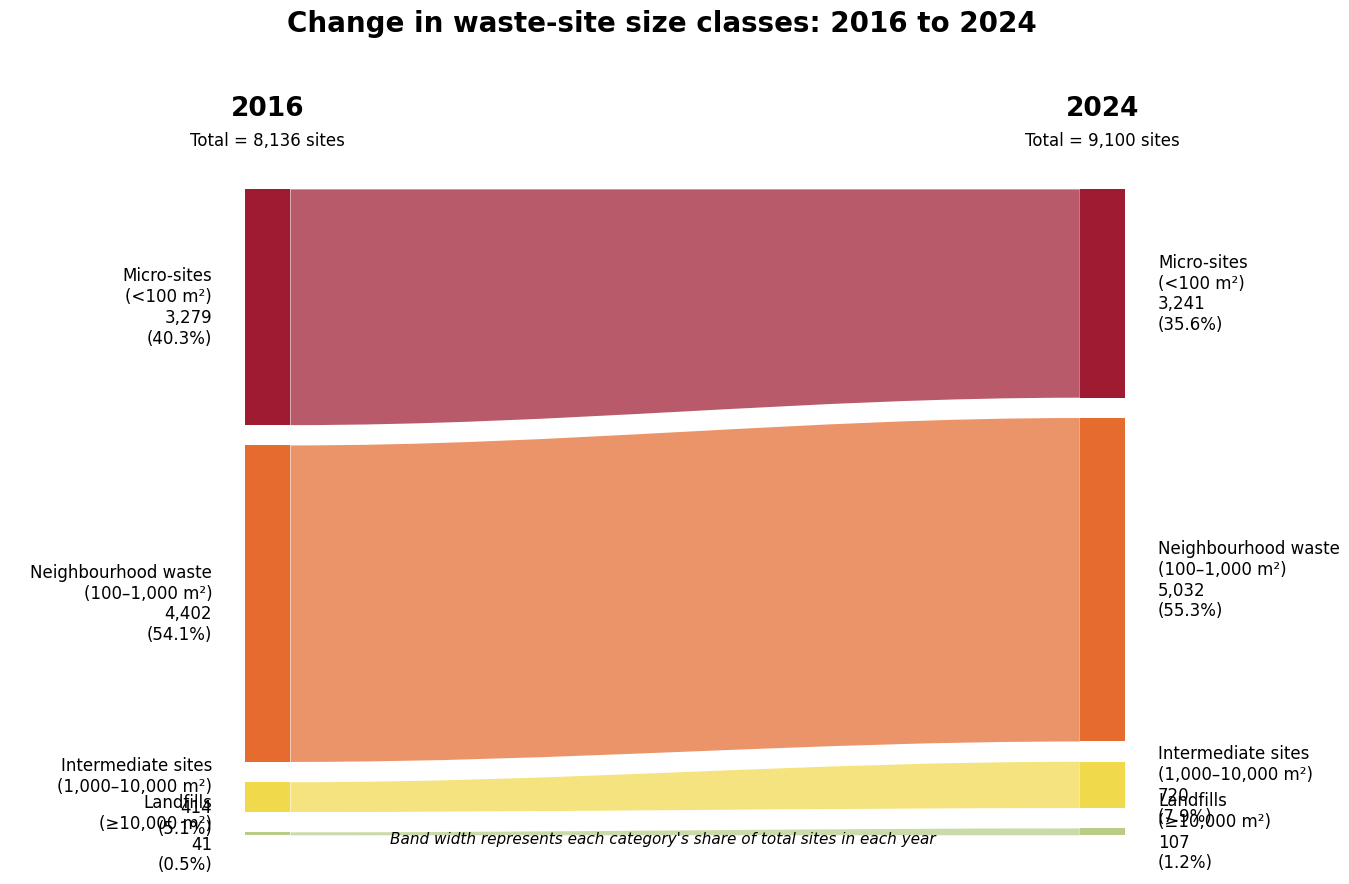

                            category  count_2016  pct_2016  count_2024  pct_2024  count_change  percentage_point_change
               Micro-sites (<100 m²)        3279      40.3        3241      35.6           -38                     -4.7
  Neighbourhood waste (100–1,000 m²)        4402      54.1        5032      55.3           630                      1.2
Intermediate sites (1,000–10,000 m²)         414       5.1         720       7.9           306                      2.8
              Landfills (≥10,000 m²)          41       0.5         107       1.2            66                      0.7


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.path import Path
from matplotlib.patches import PathPatch, Rectangle

SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"

cities = [
    "Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
    "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"
]

categories = [
    "Micro-sites\n(<100 m²)",
    "Neighbourhood waste\n(100–1,000 m²)",
    "Intermediate sites\n(1,000–10,000 m²)",
    "Landfills\n(≥10,000 m²)"
]

colors = ["#9e1b32", "#e56b2f", "#f1d94c", "#b8cc88"]

def classify_site(area):
    if area < 100:
        return 0
    elif area < 1000:
        return 1
    elif area < 10000:
        return 2
    return 3

def get_category_counts(year):
    counts = np.zeros(4, dtype=int)

    for city in cities:
        path = f"{SITES_DIR}/{year}/{city}/{city}_{year}_sites.csv"
        df = pd.read_csv(path).dropna(subset=["area"])
        classes = df["area"].apply(classify_site)

        for i in range(4):
            counts[i] += (classes == i).sum()

    return counts

counts_2016 = get_category_counts(2016)
counts_2024 = get_category_counts(2024)

total_2016 = counts_2016.sum()
total_2024 = counts_2024.sum()

pct_2016 = counts_2016 / total_2016 * 100
pct_2024 = counts_2024 / total_2024 * 100

# -------------------------------------------------------
# Plot
# -------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 9))

x_left = 0.18
x_right = 0.82
bar_width = 0.035
gap = 0.025
usable_height = 0.72

# Each side is independently normalised to its yearly total
height_2016 = counts_2016 / total_2016 * usable_height
height_2024 = counts_2024 / total_2024 * usable_height

# Positions from top to bottom
top = 0.84

y2016 = []
y2024 = []

current = top
for h in height_2016:
    y2016.append((current - h, current))
    current -= h + gap

current = top
for h in height_2024:
    y2024.append((current - h, current))
    current -= h + gap

def draw_band(x0, x1, y0_bottom, y0_top, y1_bottom, y1_top, color):
    """Smooth band whose width may differ between 2016 and 2024."""
    c = 0.35

    verts = [
        (x0, y0_top),
        (x0 + c * (x1 - x0), y0_top),
        (x1 - c * (x1 - x0), y1_top),
        (x1, y1_top),

        (x1, y1_bottom),
        (x1 - c * (x1 - x0), y1_bottom),
        (x0 + c * (x1 - x0), y0_bottom),
        (x0, y0_bottom),

        (x0, y0_top)
    ]

    codes = [
        Path.MOVETO,
        Path.CURVE4, Path.CURVE4, Path.CURVE4,
        Path.LINETO,
        Path.CURVE4, Path.CURVE4, Path.CURVE4,
        Path.CLOSEPOLY
    ]

    patch = PathPatch(
        Path(verts, codes),
        facecolor=color,
        edgecolor="none",
        alpha=0.72
    )
    ax.add_patch(patch)

# -------------------------------------------------------
# Bands + category blocks
# -------------------------------------------------------
for i in range(4):
    y0b, y0t = y2016[i]
    y1b, y1t = y2024[i]

    draw_band(
        x_left + bar_width,
        x_right,
        y0b, y0t,
        y1b, y1t,
        colors[i]
    )

    ax.add_patch(Rectangle(
        (x_left, y0b),
        bar_width,
        y0t - y0b,
        facecolor=colors[i],
        edgecolor="none"
    ))

    ax.add_patch(Rectangle(
        (x_right, y1b),
        bar_width,
        y1t - y1b,
        facecolor=colors[i],
        edgecolor="none"
    ))

# -------------------------------------------------------
# Labels
# -------------------------------------------------------
for i, category in enumerate(categories):
    y0 = np.mean(y2016[i])
    y1 = np.mean(y2024[i])

    ax.text(
        x_left - 0.025, y0,
        f"{category}\n"
        f"{counts_2016[i]:,}\n"
        f"({pct_2016[i]:.1f}%)",
        ha="right", va="center",
        fontsize=12
    )

    ax.text(
        x_right + bar_width + 0.025, y1,
        f"{category}\n"
        f"{counts_2024[i]:,}\n"
        f"({pct_2024[i]:.1f}%)",
        ha="left", va="center",
        fontsize=12
    )

# -------------------------------------------------------
# Year headings
# -------------------------------------------------------
ax.text(
    x_left + bar_width / 2, 0.94,
    "2016",
    ha="center", va="center",
    fontsize=19, fontweight="bold"
)

ax.text(
    x_left + bar_width / 2, 0.90,
    f"Total = {total_2016:,} sites",
    ha="center", va="center",
    fontsize=12
)

ax.text(
    x_right + bar_width / 2, 0.94,
    "2024",
    ha="center", va="center",
    fontsize=19, fontweight="bold"
)

ax.text(
    x_right + bar_width / 2, 0.90,
    f"Total = {total_2024:,} sites",
    ha="center", va="center",
    fontsize=12
)

ax.set_title(
    "Change in waste-site size classes: 2016 to 2024",
    fontsize=20,
    fontweight="bold",
    pad=20
)

ax.text(
    0.5, 0.035,
    "Band width represents each category's share of total sites in each year",
    ha="center",
    fontsize=11,
    style="italic"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")

plt.tight_layout()
plt.show()

# -------------------------------------------------------
# Print underlying values
# -------------------------------------------------------
summary = pd.DataFrame({
    "category": [c.replace("\n", " ") for c in categories],
    "count_2016": counts_2016,
    "pct_2016": pct_2016,
    "count_2024": counts_2024,
    "pct_2024": pct_2024,
    "count_change": counts_2024 - counts_2016,
    "percentage_point_change": pct_2024 - pct_2016
}).round(1)

print(summary.to_string(index=False))

In [ ]:
"""
For each city, at radii of 2km and 0.5km: profiles Population density, Slum
likelihood, NTL, and Building density (built morphology) for grid cells
within that radius of the nearest waste site, in 2016 vs 2024 — each year
using its OWN site list to define the "near" zone (so the zone shifts as
sites appear/disappear between years).

Control group: Stable-Absent land (DV=0 both years, Population>0) that is
ALSO outside the radius being tested — this keeps the comparison genuine
("near" vs "not near"), rather than "near" vs "land regardless of distance"
which would dilute the comparison since a lot of populated land could fall
within radius of SOME site.

DiD = near-zone %change \u2212 outside-radius-control %change.

Requires: geopandas, scipy
  !pip install geopandas scipy -q   # run first if not installed

Run in Colab after mounting Drive. Nothing saved to Drive.
"""

import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial import cKDTree

COMBINED_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Combined"
SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"

PREDICTORS = ["Population", "Slum", "NTL", "Building_density"]
RADII_KM = [0.5, 2]


def load_grid(city):
    c = city.lower()
    return pd.read_csv(f"{COMBINED_DIR}/{city}/{c}_grid30m_combined.csv")


def load_sites(city, year, drop_bottom_pct=0):
    sites = pd.read_csv(f"{SITES_DIR}/{year}/{city}/{city}_{year}_sites.csv")
    sites = sites.dropna(subset=["latitude", "longitude"])
    if drop_bottom_pct > 0:
        cutoff = sites["area"].quantile(drop_bottom_pct / 100)
        sites = sites[sites["area"] >= cutoff]
    return sites


def compute_grid_site_distances_fixed(city, grid, reference_year="2024", drop_bottom_pct=0):
    """
    Distance (m) from every grid point to the nearest site, using a SINGLE
    fixed reference site-set — so the near/control spatial zones are
    identical physical locations when comparing 2016 vs 2024 (a true panel
    comparison), rather than each year redefining the zone with its own
    sites (which lets zone composition churn confound the %change).

    reference_year: "2016", "2024", or "union" (both years' sites combined).
    """
    grid_gdf = gpd.GeoDataFrame(
        grid, geometry=gpd.points_from_xy(grid["longitude"], grid["latitude"]), crs="EPSG:4326"
    )
    utm_crs = grid_gdf.estimate_utm_crs()
    grid_gdf = grid_gdf.to_crs(utm_crs)
    grid_coords = np.column_stack([grid_gdf.geometry.x, grid_gdf.geometry.y])

    if reference_year == "union":
        sites = pd.concat([load_sites(city, 2016, drop_bottom_pct),
                            load_sites(city, 2024, drop_bottom_pct)], ignore_index=True)
    else:
        sites = load_sites(city, int(reference_year), drop_bottom_pct)

    site_gdf = gpd.GeoDataFrame(
        sites, geometry=gpd.points_from_xy(sites["longitude"], sites["latitude"]), crs="EPSG:4326"
    ).to_crs(utm_crs)
    site_coords = np.column_stack([site_gdf.geometry.x, site_gdf.geometry.y])

    tree = cKDTree(site_coords)
    dist, _ = tree.query(grid_coords, k=1)
    return dist


def pct_change(before, after):
    b_mean, a_mean = before.mean(), after.mean()
    b_med, a_med = before.median(), after.median()
    mean_pct = (a_mean - b_mean) / b_mean * 100 if b_mean != 0 else float("nan")
    median_pct = (a_med - b_med) / b_med * 100 if b_med != 0 else float("nan")
    return b_mean, a_mean, mean_pct, b_med, a_med, median_pct


def compute_radius_profile_shift(cities, radii_km=RADII_KM, predictors=PREDICTORS,
                                  drop_bottom_pct=0, site_reference="2024"):
    rows = []
    for city in cities:
        grid = load_grid(city)
        dist = compute_grid_site_distances_fixed(city, grid, site_reference, drop_bottom_pct)

        stable_absent = (grid["DV_2016"] == 0) & (grid["DV_2024"] == 0)

        for radius_km in radii_km:
            radius_m = radius_km * 1000
            near_mask = dist <= radius_m          # SAME cells for both years
            control_zone_mask = stable_absent & (dist > radius_m)  # SAME spatial zone for both years

            populated_2016 = grid["Population_2016"] > 0
            populated_2024 = grid["Population_2024"] > 0
            control_2016_mask = control_zone_mask & populated_2016
            control_2024_mask = control_zone_mask & populated_2024

            for p in predictors:
                near_b, near_a, near_mean_pct, near_bmed, near_amed, near_med_pct = pct_change(
                    grid.loc[near_mask, f"{p}_2016"], grid.loc[near_mask, f"{p}_2024"]
                )
                ctrl_b, ctrl_a, ctrl_mean_pct, ctrl_bmed, ctrl_amed, ctrl_med_pct = pct_change(
                    grid.loc[control_2016_mask, f"{p}_2016"], grid.loc[control_2024_mask, f"{p}_2024"]
                )

                rows.append({
                    "city": city, "radius_km": radius_km, "predictor": p,
                    "n_near": int(near_mask.sum()),
                    "n_control_2016": int(control_2016_mask.sum()), "n_control_2024": int(control_2024_mask.sum()),
                    "near_2016": near_b, "near_2024": near_a, "near_pct_mean": near_mean_pct,
                    "control_2016": ctrl_b, "control_2024": ctrl_a, "control_pct_mean": ctrl_mean_pct,
                    "DiD_mean": near_mean_pct - ctrl_mean_pct,
                    "near_med_2016": near_bmed, "near_med_2024": near_amed, "near_pct_median": near_med_pct,
                    "control_med_2016": ctrl_bmed, "control_med_2024": ctrl_amed, "control_pct_median": ctrl_med_pct,
                    "DiD_median": near_med_pct - ctrl_med_pct,
                })
    return pd.DataFrame(rows)


def _pretty_print_table(df, title):
    index_label = df.index.name or ""
    col_names = list(df.columns)
    idx_w = max([len(index_label)] + [len(str(i)) for i in df.index]) + 2
    col_widths = {c: max(len(str(c)), *(len(str(v)) for v in df[c])) + 2 for c in col_names}
    total_w = idx_w + sum(col_widths[c] for c in col_names)
    print("\n" + "=" * total_w)
    print(title)
    print("=" * total_w)
    print(index_label.ljust(idx_w) + "".join(str(c).rjust(col_widths[c]) for c in col_names))
    print("-" * total_w)
    for idx, row in df.iterrows():
        line = str(idx).ljust(idx_w)
        for c in col_names:
            line += str(row[c]).rjust(col_widths[c])
        print(line)
    print("=" * total_w)


def print_per_city_radius_table(shift_df, city, radius_km):
    sub = shift_df[(shift_df["city"] == city) & (shift_df["radius_km"] == radius_km)].set_index("predictor")
    cols = ["n_near", "n_control_2016", "n_control_2024",
            "near_2016", "near_2024", "near_pct_mean", "control_2016", "control_2024", "control_pct_mean", "DiD_mean"]
    _pretty_print_table(sub[cols].round(3), f"{city} \u2014 within {radius_km}km (fixed zone) vs outside-radius Stable-Absent")


def summary_table(shift_df, n_cities, radius_km, predictors=PREDICTORS, min_control_n=30):
    """min_control_n: cities where n_control_2016 or n_control_2024 falls below
    this are flagged, since a small control sample is what's most likely to
    produce the implausible/unstable percentages (see e.g. Dakar/Freetown at
    2km) — this doesn't exclude them automatically, just surfaces the risk."""
    rows = []
    sub_radius = shift_df[shift_df["radius_km"] == radius_km]
    for p in predictors:
        sub = sub_radius[sub_radius["predictor"] == p]
        n_pos = (sub["DiD_mean"] > 0).sum()
        n_neg = (sub["DiD_mean"] < 0).sum()
        majority = "+" if n_pos > n_neg else ("-" if n_neg > n_pos else "tied")
        rows.append({
            "predictor": p,
            "DiD_mean_avg": sub["DiD_mean"].mean(),
            "DiD_mean_median": sub["DiD_mean"].median(),
            "DiD_median_avg": sub["DiD_median"].mean() if p != "Building_density" else float("nan"),
            "n_positive": n_pos, "n_negative": n_neg, "majority": majority,
        })
    summary = pd.DataFrame(rows).set_index("predictor").round(2)
    summary["consistency"] = summary["n_negative"].astype(str) + f"/{n_cities} negative"
    summary = summary.sort_values("DiD_mean_avg", ascending=True)  # most negative (strongest) first

    note = " (median DiD unreliable for this predictor \u2014 near-zero baseline; NaN shown)" \
        if "Building_density" in predictors else ""
    _pretty_print_table(summary[["DiD_mean_avg", "DiD_mean_median", "DiD_median_avg", "majority", "consistency"]],
                         f"SUMMARY \u2014 radius={radius_km}km, DiD (near %\u0394 minus outside-radius control %\u0394){note}")

    # Flag cities with a thin control sample at this radius
    thin = shift_df[(shift_df["radius_km"] == radius_km) &
                     ((shift_df["n_control_2016"] < min_control_n) | (shift_df["n_control_2024"] < min_control_n))]
    thin_cities = sorted(thin["city"].unique())
    if thin_cities:
        print(f"\nWARNING: control sample n<{min_control_n} at radius={radius_km}km for: {', '.join(thin_cities)} "
              f"\u2014 DiD for these cities/predictors may be unstable, check n_control columns above.")

    return summary


# =====================================================================
# Main
# =====================================================================
if __name__ == "__main__":
    cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
              "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

    SITE_REFERENCE = "2024"  # "2016", "2024", or "union" — which sites define the fixed zone
    shift_df = compute_radius_profile_shift(cities, radii_km=RADII_KM, drop_bottom_pct=0,
                                             site_reference=SITE_REFERENCE)

    for radius_km in RADII_KM:
        for city in cities:
            print_per_city_radius_table(shift_df, city, radius_km)
        summary_table(shift_df, n_cities=len(cities), radius_km=radius_km)


Abidjan — within 0.5km (fixed zone) vs outside-radius Stable-Absent
predictor           n_near  n_control_2016  n_control_2024  near_2016  near_2024  near_pct_mean  control_2016  control_2024  control_pct_mean  DiD_mean
-------------------------------------------------------------------------------------------------------------------------------------------------------
Population         53231.0         41934.0         41963.0    143.888    176.852         22.909        59.455        74.161            24.735    -1.826
Slum               53231.0         41934.0         41963.0       0.27      0.381         40.918         0.186         0.291            56.662   -15.743
NTL                53231.0         41934.0         41963.0     17.842     29.267         64.038         13.75        25.856            88.035   -23.997
Building_density   53231.0         41934.0         41963.0      0.001      0.001         42.256           0.0         0.001            75.683   -33.427

Accra — within 0.5

LOCO analysis

LOCO (Top-6)

In [ ]:
import os
import pandas as pd
import numpy as np
import xgboost as xgb
import optuna
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score

optuna.logging.set_verbosity(optuna.logging.WARNING)

cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
          "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

top6_predictors = ["Infra_distance", "NTL", "Population", "Slum", "Arterial_roads", "Building_density"]

out_dir = "/content/drive/MyDrive/Paper_3/Processing/DV/LOCO/Top_6"
os.makedirs(out_dir, exist_ok=True)

# =====================================================================
# 1. Build stacked, top-6-only, unweighted dataset for every city
# =====================================================================

def build_city_stacked(city):
    c = city.lower()
    combined_dir = f"/content/drive/MyDrive/Paper_3/Processing/DV/Combined/{city}"
    df = pd.read_csv(f"{combined_dir}/{c}_grid30m_combined.csv")

    def year_slice(df, year, dv_col):
        cols_year = {f"{p}_{year}": p for p in top6_predictors}
        sub = df[["grid_point"] + list(cols_year.keys()) + [dv_col]].rename(columns=cols_year)
        sub["year"] = year
        sub["DV"] = df[dv_col]
        sub["city"] = city
        return sub

    stacked = pd.concat([year_slice(df, 2016, "DV_2016"), year_slice(df, 2024, "DV_2024")], ignore_index=True)
    stacked["target"] = (stacked["DV"] > 0).astype(int)
    stacked["fold_group"] = stacked["city"] + "_" + stacked["grid_point"].astype(str)
    return stacked

print("Building per-city stacked datasets (top-6 predictors)...")
city_data = {city: build_city_stacked(city) for city in cities}
full_pooled = pd.concat(city_data.values(), ignore_index=True)
print(f"Full pooled dataset: {len(full_pooled):,} rows across {len(cities)} cities")

# =====================================================================
# 2. Light tuning on a subsample of the pooled dataset
# =====================================================================

def logging_callback(study, trial):
    print(f"Trial {trial.number} done — value: {trial.value:.4f} | best so far: {study.best_value:.4f}")

TUNE_SAMPLE_SIZE = 800_000
tune_sample = full_pooled.groupby("city", group_keys=False).apply(
    lambda g: g.sample(n=min(len(g), TUNE_SAMPLE_SIZE // len(cities)), random_state=42)
)
X_tune, y_tune, groups_tune = tune_sample[top6_predictors], tune_sample["target"], tune_sample["fold_group"]

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 300),
        "max_depth": trial.suggest_int("max_depth", 2, 6),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "random_state": 42,
        "eval_metric": "logloss",
    }
    gkf = GroupKFold(n_splits=5)
    aucs = []
    for tr_i, val_i in gkf.split(X_tune, y_tune, groups=groups_tune):
        m = xgb.XGBClassifier(**params)
        m.fit(X_tune.iloc[tr_i], y_tune.iloc[tr_i])
        p = m.predict_proba(X_tune.iloc[val_i])[:, 1]
        aucs.append(roc_auc_score(y_tune.iloc[val_i], p))
    return np.mean(aucs)

print(f"\nLight tuning on {len(tune_sample):,}-row subsample (15 trials, timeout 20 min)...")
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=15, timeout=1200, callbacks=[logging_callback], show_progress_bar=False)
shared_params = study.best_params.copy()
shared_params.update({"random_state": 42, "eval_metric": "logloss"})
print(f"Shared params tuned — CV AUC (on subsample): {study.best_value:.4f}")
print(shared_params)

# =====================================================================
# 3. LOCO loop: train on 9, predict on 1, repeat for all 10
# =====================================================================

summary_rows = []
PCTS_CAPTURE = [50, 40, 30, 25]

for held_out in cities:
    train_data = pd.concat([city_data[c] for c in cities if c != held_out], ignore_index=True)
    test_data = city_data[held_out].copy()

    X_train, y_train = train_data[top6_predictors], train_data["target"]
    X_test = test_data[top6_predictors]

    model = xgb.XGBClassifier(**shared_params)
    model.fit(X_train, y_train)

    test_data["pred_proba"] = model.predict_proba(X_test)[:, 1]

    pred_cols = ["grid_point", "year", "DV", "target", "pred_proba"]
    test_data[pred_cols].to_csv(f"{out_dir}/{held_out.lower()}_loco_predictions.csv", index=False)

    test_data["decile"] = pd.qcut(test_data["pred_proba"].rank(method="first"), 10, labels=False) + 1
    calib = test_data.groupby("decile")["DV"].agg(["mean", "median", "count"]).reset_index()
    calib.to_csv(f"{out_dir}/{held_out.lower()}_loco_calibration.csv", index=False)

    test_sorted = test_data.sort_values("pred_proba", ascending=False).reset_index(drop=True)
    n_total = len(test_sorted)
    total_dv = test_sorted["DV"].sum()
    total_present = (test_sorted["target"] == 1).sum()

    row = {"city": held_out, "n_cells": n_total, "total_true_present": total_present}
    for pct in PCTS_CAPTURE:
        n_select = int(n_total * pct / 100)
        selected = test_sorted.iloc[:n_select]
        hit_rate = (selected["target"] == 1).sum() / total_present if total_present > 0 else np.nan
        dv_capture = selected["DV"].sum() / total_dv if total_dv > 0 else np.nan
        row[f"hit_rate_top{pct}"] = hit_rate
        row[f"dv_capture_top{pct}"] = dv_capture

    row["test_auc"] = roc_auc_score(test_data["target"], test_data["pred_proba"])
    summary_rows.append(row)

    print(f"{held_out}: test AUC={row['test_auc']:.4f} | "
          f"DV capture @top25%={row['dv_capture_top25']:.3f} | @top50%={row['dv_capture_top50']:.3f}")

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(f"{out_dir}/loco_summary_results.csv", index=False)

print(f"\nSaved Top-6 LOCO predictions, calibration tables, and summary results to: {out_dir}")

Building per-city stacked datasets (top-6 predictors)...
Full pooled dataset: 7,140,976 rows across 10 cities


/tmp/ipykernel_2407/3769536383.py:54: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tune_sample = full_pooled.groupby("city", group_keys=False).apply(



Light tuning on 800,000-row subsample (15 trials, timeout 20 min)...
Trial 0 done — value: 0.8053 | best so far: 0.8053
Trial 1 done — value: 0.7924 | best so far: 0.8053
Trial 2 done — value: 0.8108 | best so far: 0.8108
Trial 3 done — value: 0.8095 | best so far: 0.8108
Trial 4 done — value: 0.8204 | best so far: 0.8204
Trial 5 done — value: 0.7907 | best so far: 0.8204
Trial 6 done — value: 0.7827 | best so far: 0.8204
Trial 7 done — value: 0.7959 | best so far: 0.8204
Trial 8 done — value: 0.8007 | best so far: 0.8204
Trial 9 done — value: 0.7930 | best so far: 0.8204
Trial 10 done — value: 0.8422 | best so far: 0.8422
Trial 11 done — value: 0.8390 | best so far: 0.8422
Trial 12 done — value: 0.8413 | best so far: 0.8422
Trial 13 done — value: 0.8409 | best so far: 0.8422
Trial 14 done — value: 0.8242 | best so far: 0.8422
Shared params tuned — CV AUC (on subsample): 0.8422
{'n_estimators': 210, 'max_depth': 6, 'learning_rate': 0.29998787143467526, 'subsample': 0.9915244095072102,

All predictors

In [ ]:
import pandas as pd
import numpy as np
import xgboost as xgb
import optuna
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score

optuna.logging.set_verbosity(optuna.logging.WARNING)

cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
          "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

all9_predictors = ["Population", "Slum", "NTL", "Dist_open_edge", "Building_density",
                    "Building_height", "Infra_distance", "Arterial_roads", "Tertiary_roads"]

# =====================================================================
# 1. Build stacked, all-9-predictor, unweighted dataset for every city
# =====================================================================

def build_city_stacked(city):
    c = city.lower()
    combined_dir = f"/content/drive/MyDrive/Paper_3/Processing/DV/Combined/{city}"
    df = pd.read_csv(f"{combined_dir}/{c}_grid30m_combined.csv")

    def year_slice(df, year, dv_col):
        cols_year = {f"{p}_{year}": p for p in all9_predictors}
        sub = df[["grid_point"] + list(cols_year.keys()) + [dv_col]].rename(columns=cols_year)
        sub["year"] = year
        sub["DV"] = df[dv_col]
        sub["city"] = city
        return sub

    stacked = pd.concat([year_slice(df, 2016, "DV_2016"), year_slice(df, 2024, "DV_2024")], ignore_index=True)
    stacked["target"] = (stacked["DV"] > 0).astype(int)
    stacked["fold_group"] = stacked["city"] + "_" + stacked["grid_point"].astype(str)
    return stacked

print("Building per-city stacked datasets (all 9 predictors)...")
city_data = {city: build_city_stacked(city) for city in cities}
full_pooled = pd.concat(city_data.values(), ignore_index=True)
print(f"Full pooled dataset: {len(full_pooled):,} rows")

# =====================================================================
# 2. Light tuning on a subsample of the pooled dataset
# =====================================================================

def logging_callback(study, trial):
    print(f"Trial {trial.number} done — value: {trial.value:.4f} | best so far: {study.best_value:.4f}")

TUNE_SAMPLE_SIZE = 800_000
tune_sample = full_pooled.groupby("city", group_keys=False).apply(
    lambda g: g.sample(n=min(len(g), TUNE_SAMPLE_SIZE // len(cities)), random_state=42)
)
X_tune, y_tune, groups_tune = tune_sample[all9_predictors], tune_sample["target"], tune_sample["fold_group"]

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 300),
        "max_depth": trial.suggest_int("max_depth", 2, 6),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "random_state": 42,
        "eval_metric": "logloss",
    }
    gkf = GroupKFold(n_splits=5)
    aucs = []
    for tr_i, val_i in gkf.split(X_tune, y_tune, groups=groups_tune):
        m = xgb.XGBClassifier(**params)
        m.fit(X_tune.iloc[tr_i], y_tune.iloc[tr_i])
        p = m.predict_proba(X_tune.iloc[val_i])[:, 1]
        aucs.append(roc_auc_score(y_tune.iloc[val_i], p))
    return np.mean(aucs)

print(f"\nLight tuning on {len(tune_sample):,}-row subsample (15 trials, timeout 20 min)...")
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=15, timeout=1200, callbacks=[logging_callback], show_progress_bar=False)
shared_params = study.best_params.copy()
shared_params.update({"random_state": 42, "eval_metric": "logloss"})
print(f"Shared params tuned — CV AUC (on subsample): {study.best_value:.4f}\n")

# =====================================================================
# 3. LOCO loop — in-memory only, nothing saved to disk
# =====================================================================

summary_rows = []
PCTS_CAPTURE = [50, 40, 30, 25]

for held_out in cities:
    train_data = pd.concat([city_data[c] for c in cities if c != held_out], ignore_index=True)
    test_data = city_data[held_out].copy()

    X_train, y_train = train_data[all9_predictors], train_data["target"]
    X_test = test_data[all9_predictors]

    model = xgb.XGBClassifier(**shared_params)
    model.fit(X_train, y_train)
    test_data["pred_proba"] = model.predict_proba(X_test)[:, 1]

    test_sorted = test_data.sort_values("pred_proba", ascending=False).reset_index(drop=True)
    n_total = len(test_sorted)
    total_dv = test_sorted["DV"].sum()
    total_present = (test_sorted["target"] == 1).sum()

    row = {"city": held_out}
    for pct in PCTS_CAPTURE:
        n_select = int(n_total * pct / 100)
        selected = test_sorted.iloc[:n_select]
        row[f"dv_capture_top{pct}"] = selected["DV"].sum() / total_dv if total_dv > 0 else np.nan

    row["test_auc"] = roc_auc_score(test_data["target"], test_data["pred_proba"])
    summary_rows.append(row)
    print(f"{held_out}: test AUC={row['test_auc']:.4f} | "
          f"DV capture @top25%={row['dv_capture_top25']:.3f} | @top50%={row['dv_capture_top50']:.3f}")

summary_df = pd.DataFrame(summary_rows)
print("\n" + "=" * 70)
print("ALL-9-PREDICTOR LOCO SUMMARY (in-memory only)")
print("=" * 70)
print(summary_df.to_string(index=False))

Building per-city stacked datasets (all 9 predictors)...
Full pooled dataset: 7,140,976 rows


/tmp/ipykernel_2407/1476998844.py:51: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tune_sample = full_pooled.groupby("city", group_keys=False).apply(



Light tuning on 800,000-row subsample (15 trials, timeout 20 min)...
Trial 0 done — value: 0.7950 | best so far: 0.7950
Trial 1 done — value: 0.8019 | best so far: 0.8019
Trial 2 done — value: 0.7997 | best so far: 0.8019
Trial 3 done — value: 0.7799 | best so far: 0.8019
Trial 4 done — value: 0.8196 | best so far: 0.8196
Trial 5 done — value: 0.8375 | best so far: 0.8375
Trial 6 done — value: 0.7919 | best so far: 0.8375
Trial 7 done — value: 0.7996 | best so far: 0.8375
Trial 8 done — value: 0.7981 | best so far: 0.8375
Trial 9 done — value: 0.7983 | best so far: 0.8375
Trial 10 done — value: 0.8313 | best so far: 0.8375
Trial 11 done — value: 0.8323 | best so far: 0.8375
Trial 12 done — value: 0.8374 | best so far: 0.8375
Trial 13 done — value: 0.8230 | best so far: 0.8375
Trial 14 done — value: 0.8195 | best so far: 0.8375
Shared params tuned — CV AUC (on subsample): 0.8375

Abidjan: test AUC=0.7416 | DV capture @top25%=0.428 | @top50%=0.760
Accra: test AUC=0.6123 | DV capture @to

In [ ]:
import pandas as pd

SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"

cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
          "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

HECTARE_M2 = 500
TOLERANCE_M2 = 475  # "slightly smaller than 1 ha" cutoff — adjust as needed

rows = []

for city in cities:
    for year in [2016, 2024]:
        try:
            sites = pd.read_csv(f"{SITES_DIR}/{year}/{city}/{city}_{year}_sites.csv")
            sites = sites.dropna(subset=["area"])

            n_total = len(sites)
            n_strict_1ha = (sites["area"] >= HECTARE_M2).sum()
            n_with_tolerance = (sites["area"] >= TOLERANCE_M2).sum()

            rows.append({
                "city": city, "year": year, "n_total_sites": n_total,
                "n_sites_>=500m2_strict": n_strict_1ha,
                "n_sites_>=0.95pct_tolerance": n_with_tolerance,
            })
        except FileNotFoundError as e:
            print(f"WARNING: {city} {year} — file not found ({e})")

results_df = pd.DataFrame(rows)
print(results_df.to_string(index=False))

        city  year  n_total_sites  n_sites_>=500m2_strict  n_sites_>=0.95pct_tolerance
     Abidjan  2016            484                      63                           67
     Abidjan  2024            630                      92                           98
       Accra  2016            795                     139                          147
       Accra  2024            552                     209                          216
       Dakar  2016            146                      36                           38
       Dakar  2024            281                      39                           41
    Freetown  2016            312                      33                           36
    Freetown  2024            487                      47                           48
Johannesburg  2016           2007                     204                          218
Johannesburg  2024           2976                     488                          513
     Kampala  2016            988          

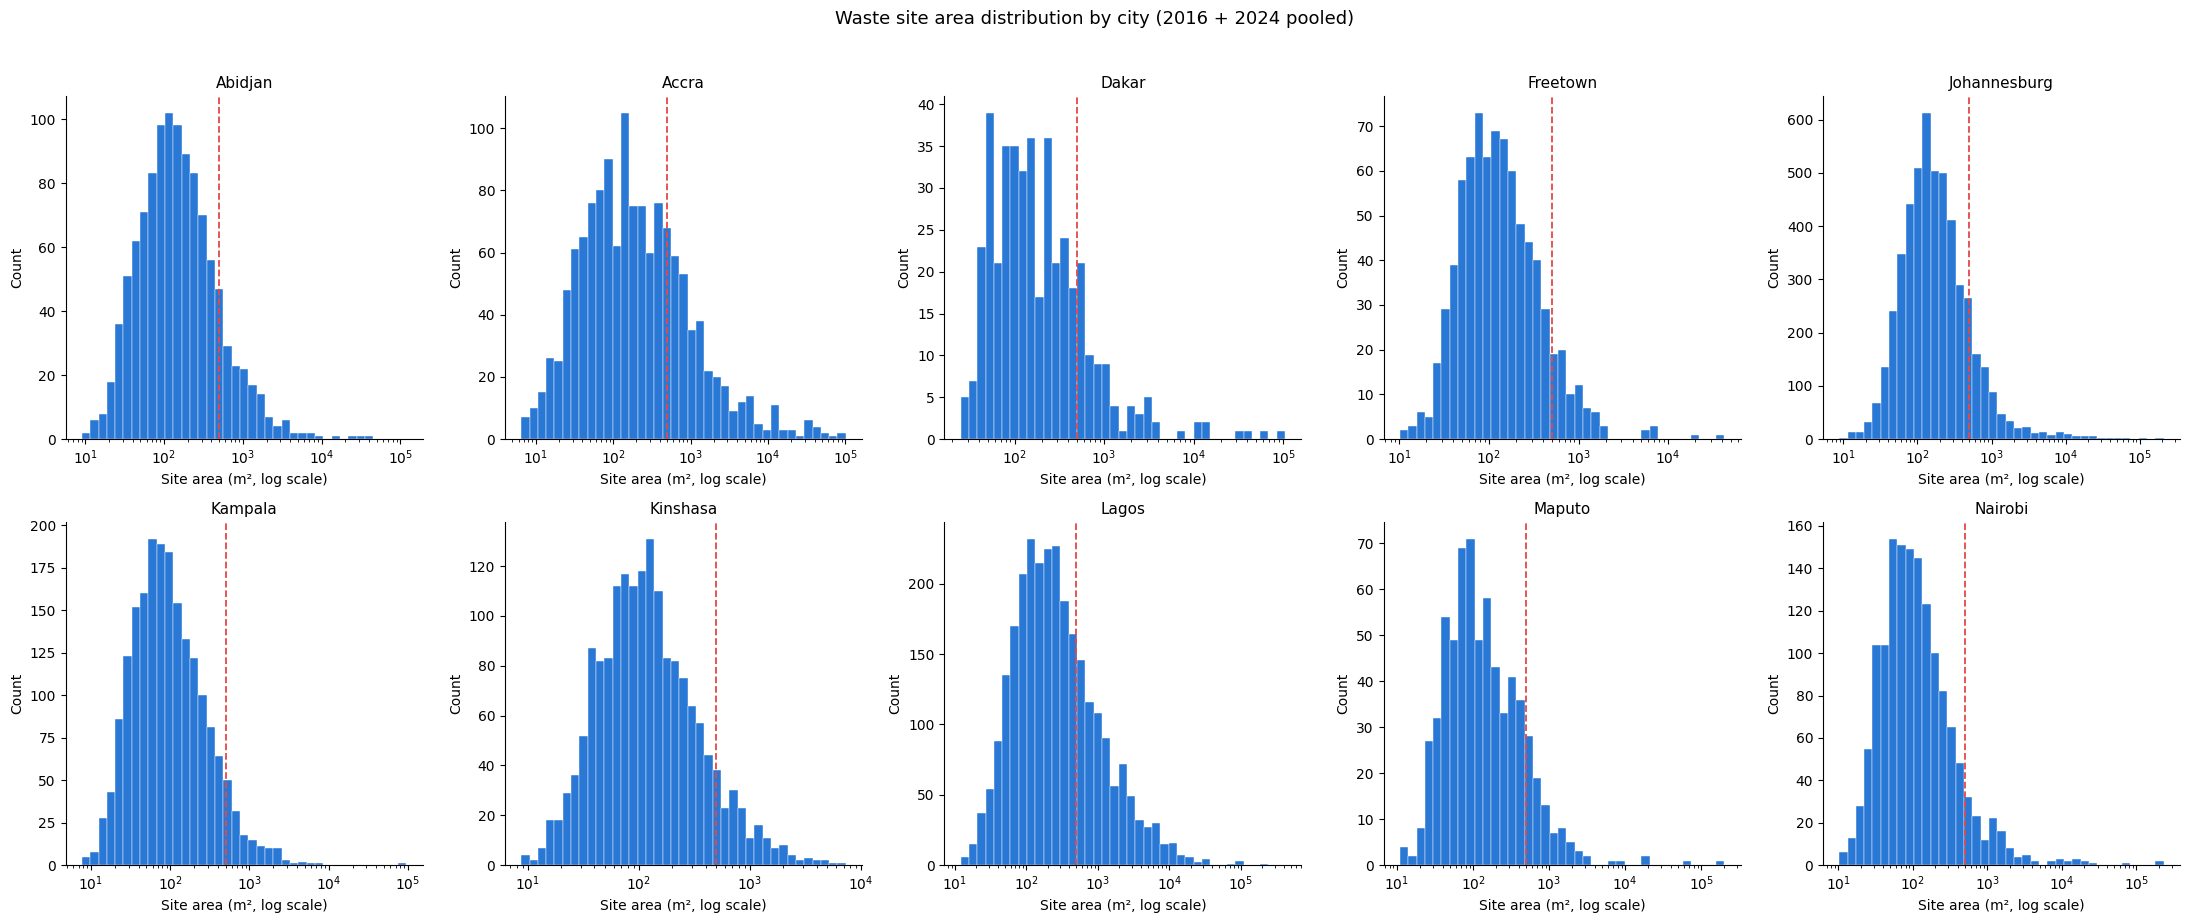

In [ ]:
"""
Simple per-city histogram of waste site areas (2016+2024 pooled), on a
log-scale x-axis with log-spaced bins — lets you see visually whether
there's a jump/gap in site sizes (small neighbourhood accumulations vs
large sites), which a linear-scale histogram would hide since site areas
are heavily right-skewed.

Run in Colab after mounting Drive. Not saved to Drive.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"
cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
          "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]


def load_pooled_areas(city):
    areas = []
    for year in [2016, 2024]:
        try:
            sites = pd.read_csv(f"{SITES_DIR}/{year}/{city}/{city}_{year}_sites.csv")
            areas.append(sites["area"].dropna())
        except FileNotFoundError:
            print(f"WARNING: {city} {year} \u2014 file not found")
    return pd.concat(areas, ignore_index=True) if areas else pd.Series(dtype=float)


fig, axes = plt.subplots(2, 5, figsize=(22, 9))

for i, city in enumerate(cities):
    ax = axes[i // 5][i % 5]
    areas = load_pooled_areas(city)
    areas = areas[areas > 0]  # log-scale can't include zero/negative

    bins = np.logspace(np.log10(areas.min()), np.log10(areas.max()), 40)
    ax.hist(areas, bins=bins, color="#2a78d6", edgecolor="white", linewidth=0.3)
    ax.axvline(500, color="#e34948", linestyle="--", linewidth=1.3)
    ax.set_xscale("log")
    ax.set_title(city, fontsize=11)
    ax.set_xlabel("Site area (m\u00b2, log scale)")
    ax.set_ylabel("Count")
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Waste site area distribution by city (2016 + 2024 pooled)", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

In [ ]:
import os
import pandas as pd
import numpy as np
import xgboost as xgb
import optuna
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score

optuna.logging.set_verbosity(optuna.logging.WARNING)

cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
          "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

top5_predictors = ["Infra_distance", "NTL", "Population", "Slum", "Arterial_roads"]

out_dir = "/content/drive/MyDrive/Paper_3/Processing/DV/LOCO"
os.makedirs(out_dir, exist_ok=True)

# =====================================================================
# 1. Build stacked, top-5-only, unweighted dataset for every city
# =====================================================================

def build_city_stacked(city):
    c = city.lower()
    combined_dir = f"/content/drive/MyDrive/Paper_3/Processing/DV/Combined/{city}"
    df = pd.read_csv(f"{combined_dir}/{c}_grid30m_combined.csv")

    def year_slice(df, year, dv_col):
        cols_year = {f"{p}_{year}": p for p in top5_predictors}
        sub = df[["grid_point"] + list(cols_year.keys()) + [dv_col]].rename(columns=cols_year)
        sub["year"] = year
        sub["DV"] = df[dv_col]
        sub["city"] = city
        return sub

    stacked = pd.concat([year_slice(df, 2016, "DV_2016"), year_slice(df, 2024, "DV_2024")], ignore_index=True)
    stacked["target"] = (stacked["DV"] > 0).astype(int)
    stacked["fold_group"] = stacked["city"] + "_" + stacked["grid_point"].astype(str)
    return stacked

print("Building per-city stacked datasets...")
city_data = {city: build_city_stacked(city) for city in cities}
full_pooled = pd.concat(city_data.values(), ignore_index=True)
print(f"Full pooled dataset: {len(full_pooled):,} rows across {len(cities)} cities")

# =====================================================================
# 2. Light tuning ONCE on the full pooled (all 10 cities) dataset
# =====================================================================

def logging_callback(study, trial):
    print(f"Trial {trial.number} done — value: {trial.value:.4f} | best so far: {study.best_value:.4f}")

# --- Subsample for tuning only ---
TUNE_SAMPLE_SIZE = 800_000
tune_sample = full_pooled.groupby("city", group_keys=False).apply(
    lambda g: g.sample(n=min(len(g), TUNE_SAMPLE_SIZE // len(cities)), random_state=42)
)
X_tune, y_tune, groups_tune = tune_sample[top5_predictors], tune_sample["target"], tune_sample["fold_group"]

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 300),      # narrowed
        "max_depth": trial.suggest_int("max_depth", 2, 6),                # narrowed
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "random_state": 42,
        "eval_metric": "logloss",
    }
    gkf = GroupKFold(n_splits=5)
    aucs = []
    for tr_i, val_i in gkf.split(X_tune, y_tune, groups=groups_tune):
        m = xgb.XGBClassifier(**params)
        m.fit(X_tune.iloc[tr_i], y_tune.iloc[tr_i])
        p = m.predict_proba(X_tune.iloc[val_i])[:, 1]
        aucs.append(roc_auc_score(y_tune.iloc[val_i], p))
    return np.mean(aucs)

print(f"\nLight tuning on {len(tune_sample):,}-row subsample (15 trials, timeout 20 min)...")
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=15, timeout=1200, callbacks=[logging_callback], show_progress_bar=False)
shared_params = study.best_params.copy()
shared_params.update({"random_state": 42, "eval_metric": "logloss"})
print(f"Shared params tuned — CV AUC (on subsample): {study.best_value:.4f}")

# =====================================================================
# 3. LOCO loop: train on 9, predict on 1, repeat for all 10
# =====================================================================

summary_rows = []
PCTS_CAPTURE = [50, 40, 30, 25]

for held_out in cities:
    train_data = pd.concat([city_data[c] for c in cities if c != held_out], ignore_index=True)
    test_data = city_data[held_out].copy()

    # --- Tune on THIS fold's training data only (held-out city never involved) ---
    tune_sample = train_data.groupby("city", group_keys=False).apply(
        lambda g: g.sample(n=min(len(g), TUNE_SAMPLE_SIZE // (len(cities) - 1)), random_state=42)
    )
    X_tune, y_tune, groups_tune = tune_sample[top5_predictors], tune_sample["target"], tune_sample["fold_group"]

    def objective(trial):
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 100, 300),
            "max_depth": trial.suggest_int("max_depth", 2, 6),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            "subsample": trial.suggest_float("subsample", 0.5, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
            "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
            "random_state": 42,
            "eval_metric": "logloss",
        }
        gkf = GroupKFold(n_splits=5)
        aucs = []
        for tr_i, val_i in gkf.split(X_tune, y_tune, groups=groups_tune):
            m = xgb.XGBClassifier(**params)
            m.fit(X_tune.iloc[tr_i], y_tune.iloc[tr_i])
            p = m.predict_proba(X_tune.iloc[val_i])[:, 1]
            aucs.append(roc_auc_score(y_tune.iloc[val_i], p))
        return np.mean(aucs)

    study = optuna.create_study(direction="maximize")
    study.optimize(objective, n_trials=15, timeout=1200, callbacks=[logging_callback], show_progress_bar=False)
    fold_params = study.best_params.copy()
    fold_params.update({"random_state": 42, "eval_metric": "logloss"})
    print(f"{held_out} fold — tuned on 9 cities only, CV AUC: {study.best_value:.4f}")

    X_train, y_train = train_data[top5_predictors], train_data["target"]
    X_test = test_data[top5_predictors]

    model = xgb.XGBClassifier(**fold_params)
    model.fit(X_train, y_train)

    test_data["pred_proba"] = model.predict_proba(X_test)[:, 1]

    # --- Save per-city predictions ---
    pred_cols = ["grid_point", "year", "DV", "target", "pred_proba"]
    test_data[pred_cols].to_csv(f"{out_dir}/{held_out.lower()}_loco_predictions.csv", index=False)

    # --- Calibration deciles ---
    test_data["decile"] = pd.qcut(test_data["pred_proba"].rank(method="first"), 10, labels=False) + 1
    calib = test_data.groupby("decile")["DV"].agg(["mean", "median", "count"]).reset_index()
    calib.to_csv(f"{out_dir}/{held_out.lower()}_loco_calibration.csv", index=False)

    # --- Capture-rate at each threshold ---
    test_sorted = test_data.sort_values("pred_proba", ascending=False).reset_index(drop=True)
    n_total = len(test_sorted)
    total_dv = test_sorted["DV"].sum()
    total_present = (test_sorted["target"] == 1).sum()

    row = {"city": held_out, "n_cells": n_total, "total_true_present": total_present}
    for pct in PCTS_CAPTURE:
        n_select = int(n_total * pct / 100)
        selected = test_sorted.iloc[:n_select]
        hit_rate = (selected["target"] == 1).sum() / total_present if total_present > 0 else np.nan
        dv_capture = selected["DV"].sum() / total_dv if total_dv > 0 else np.nan
        row[f"hit_rate_top{pct}"] = hit_rate
        row[f"dv_capture_top{pct}"] = dv_capture

    row["test_auc"] = roc_auc_score(test_data["target"], test_data["pred_proba"])
    row["best_params"] = fold_params
    summary_rows.append(row)

    print(f"{held_out}: test AUC={row['test_auc']:.4f} | "
          f"DV capture @top25%={row['dv_capture_top25']:.3f} | @top50%={row['dv_capture_top50']:.3f}")

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(f"{out_dir}/loco_summary_results.csv", index=False)

print(f"\nSaved LOCO predictions, calibration tables, and summary results to: {out_dir}")

Building per-city stacked datasets...
Full pooled dataset: 7,140,466 rows across 10 cities


/tmp/ipykernel_883/2813599731.py:55: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tune_sample = full_pooled.groupby("city", group_keys=False).apply(



Light tuning on 800,000-row subsample (15 trials, timeout 20 min)...
Trial 0 done — value: 0.7924 | best so far: 0.7924
Trial 1 done — value: 0.7961 | best so far: 0.7961
Trial 2 done — value: 0.8491 | best so far: 0.8491
Trial 3 done — value: 0.7850 | best so far: 0.8491
Trial 4 done — value: 0.7774 | best so far: 0.8491
Trial 5 done — value: 0.8085 | best so far: 0.8491
Trial 6 done — value: 0.7992 | best so far: 0.8491
Trial 7 done — value: 0.7937 | best so far: 0.8491
Trial 8 done — value: 0.7964 | best so far: 0.8491
Trial 9 done — value: 0.8183 | best so far: 0.8491
Trial 10 done — value: 0.8578 | best so far: 0.8578
Trial 11 done — value: 0.8589 | best so far: 0.8589
Trial 12 done — value: 0.8592 | best so far: 0.8592
Trial 13 done — value: 0.8584 | best so far: 0.8592
Trial 14 done — value: 0.8359 | best so far: 0.8592
Shared params tuned — CV AUC (on subsample): 0.8592


/tmp/ipykernel_883/2813599731.py:99: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tune_sample = train_data.groupby("city", group_keys=False).apply(


Trial 0 done — value: 0.8143 | best so far: 0.8143
Trial 1 done — value: 0.7886 | best so far: 0.8143
Trial 2 done — value: 0.7882 | best so far: 0.8143
Trial 3 done — value: 0.7763 | best so far: 0.8143
Trial 4 done — value: 0.7801 | best so far: 0.8143
Trial 5 done — value: 0.8340 | best so far: 0.8340
Trial 6 done — value: 0.7783 | best so far: 0.8340
Trial 7 done — value: 0.8199 | best so far: 0.8340
Trial 8 done — value: 0.7755 | best so far: 0.8340
Trial 9 done — value: 0.8154 | best so far: 0.8340
Trial 10 done — value: 0.8257 | best so far: 0.8340
Trial 11 done — value: 0.8255 | best so far: 0.8340
Trial 12 done — value: 0.8467 | best so far: 0.8467
Trial 13 done — value: 0.8324 | best so far: 0.8467
Trial 14 done — value: 0.8271 | best so far: 0.8467
Abidjan fold — tuned on 9 cities only, CV AUC: 0.8467
Abidjan: test AUC=0.7217 | DV capture @top25%=0.409 | @top50%=0.729


...

Trial 0 done — value: 0.7930 | best so far: 0.7930
Trial 1 done — value: 0.8359 | best so far: 0.8359
Trial 2 done — value: 0.8202 | best so far: 0.8359
Trial 3 done — value: 0.8149 | best so far: 0.8359
Trial 4 done — value: 0.8113 | best so far: 0.8359
Trial 5 done — value: 0.8314 | best so far: 0.8359
Trial 6 done — value: 0.8322 | best so far: 0.8359
Trial 7 done — value: 0.8367 | best so far: 0.8367
Trial 8 done — value: 0.8034 | best so far: 0.8367
Trial 9 done — value: 0.7896 | best so far: 0.8367
Trial 10 done — value: 0.7998 | best so far: 0.8367
Trial 11 done — value: 0.8402 | best so far: 0.8402
Trial 12 done — value: 0.8418 | best so far: 0.8418
Trial 13 done — value: 0.8376 | best so far: 0.8418
Trial 14 done — value: 0.8444 | best so far: 0.8444
Lagos fold — tuned on 9 cities only, CV AUC: 0.8444
Lagos: test AUC=0.6513 | DV capture @top25%=0.372 | @top50%=0.650


/tmp/ipykernel_883/2813599731.py:99: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tune_sample = train_data.groupby("city", group_keys=False).apply(


Trial 0 done — value: 0.8032 | best so far: 0.8032
Trial 1 done — value: 0.7944 | best so far: 0.8032
Trial 2 done — value: 0.8266 | best so far: 0.8266
Trial 3 done — value: 0.8386 | best so far: 0.8386
Trial 4 done — value: 0.8601 | best so far: 0.8601
Trial 5 done — value: 0.8254 | best so far: 0.8601
Trial 6 done — value: 0.8490 | best so far: 0.8601
Trial 7 done — value: 0.8227 | best so far: 0.8601
Trial 8 done — value: 0.8381 | best so far: 0.8601
Trial 9 done — value: 0.8114 | best so far: 0.8601
Trial 10 done — value: 0.7960 | best so far: 0.8601
Trial 11 done — value: 0.8478 | best so far: 0.8601
Trial 12 done — value: 0.8317 | best so far: 0.8601
Trial 13 done — value: 0.8536 | best so far: 0.8601
Trial 14 done — value: 0.8398 | best so far: 0.8601
Maputo fold — tuned on 9 cities only, CV AUC: 0.8601
Maputo: test AUC=0.6356 | DV capture @top25%=0.462 | @top50%=0.711


/tmp/ipykernel_883/2813599731.py:99: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tune_sample = train_data.groupby("city", group_keys=False).apply(


Trial 0 done — value: 0.8227 | best so far: 0.8227
Trial 1 done — value: 0.8204 | best so far: 0.8227
Trial 2 done — value: 0.7968 | best so far: 0.8227
Trial 3 done — value: 0.7967 | best so far: 0.8227
Trial 4 done — value: 0.8496 | best so far: 0.8496
Trial 5 done — value: 0.7716 | best so far: 0.8496
Trial 6 done — value: 0.8129 | best so far: 0.8496
Trial 7 done — value: 0.8161 | best so far: 0.8496
Trial 8 done — value: 0.8314 | best so far: 0.8496
Trial 9 done — value: 0.8127 | best so far: 0.8496
Trial 10 done — value: 0.8102 | best so far: 0.8496
Trial 11 done — value: 0.8372 | best so far: 0.8496
Trial 12 done — value: 0.8481 | best so far: 0.8496
Trial 13 done — value: 0.8483 | best so far: 0.8496
Trial 14 done — value: 0.8491 | best so far: 0.8496
Nairobi fold — tuned on 9 cities only, CV AUC: 0.8496
Nairobi: test AUC=0.6798 | DV capture @top25%=0.463 | @top50%=0.706

Saved LOCO predictions, calibration tables, and summary results to: /content/drive/MyDrive/Paper_3/Processi

LOCO SUMMARY — AUC, hit-rate, and DV-mass capture per held-out city
        city  n_cells  total_true_present  hit_rate_top50  dv_capture_top50  hit_rate_top40  dv_capture_top40  hit_rate_top30  dv_capture_top30  hit_rate_top25  dv_capture_top25  test_auc                                                                                                                                                                                                                best_params
     Abidjan   288052              157103        0.643380          0.728510        0.537106          0.624723        0.419082          0.486906        0.355862          0.409282  0.721713   {'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.2983000079911031, 'subsample': 0.8329465063159214, 'colsample_bytree': 0.7763650230083634, 'min_child_weight': 1, 'random_state': 42, 'eval_metric': 'logloss'}
       Accra  1228316              468336        0.563918          0.546863        0.453437          0.445396        0

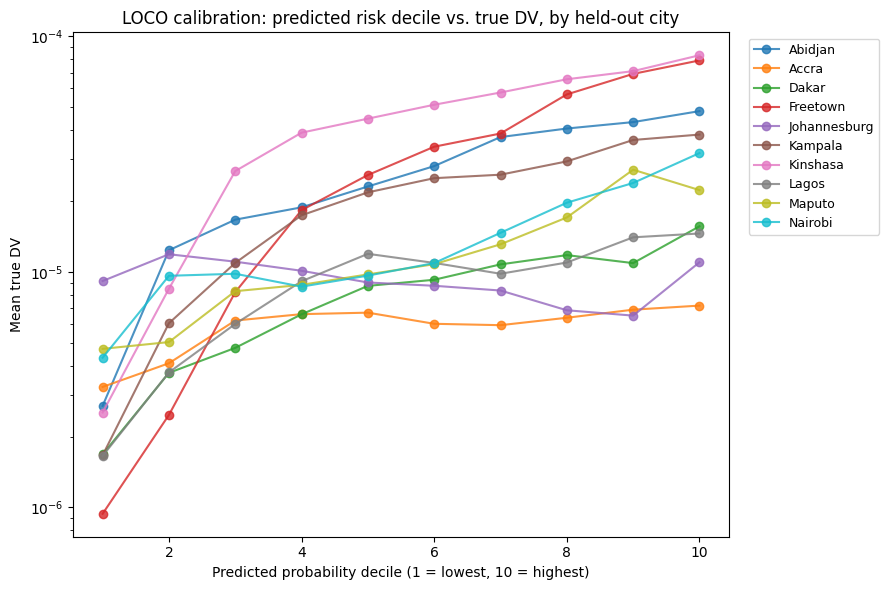

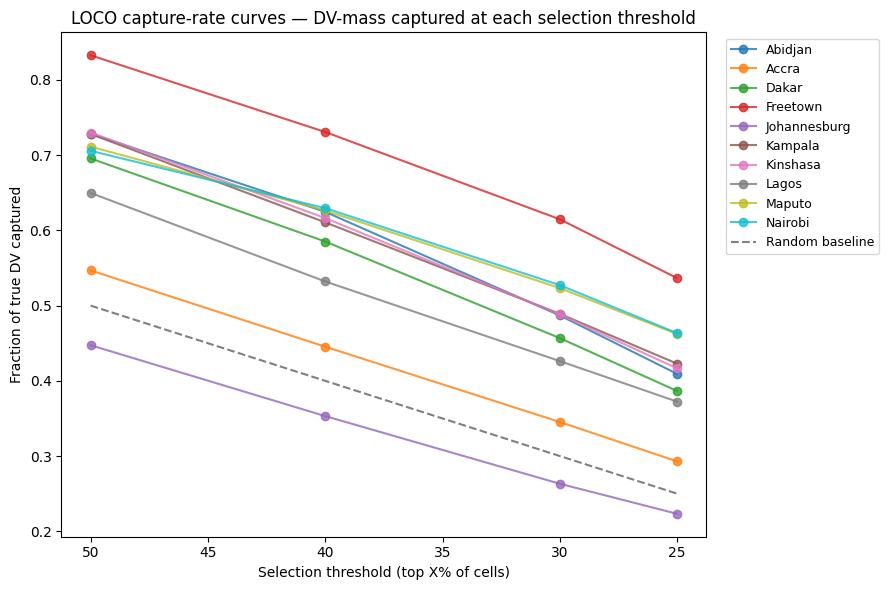

        city  n_cells  total_true_present  hit_rate_top50  dv_capture_top50  hit_rate_top40  dv_capture_top40  hit_rate_top30  dv_capture_top30  hit_rate_top25  dv_capture_top25  test_auc
     Abidjan   288052              157103        0.643380          0.728510        0.537106          0.624723        0.419082          0.486906        0.355862          0.409282  0.721713
       Accra  1228316              468336        0.563918          0.546863        0.453437          0.445396        0.338834          0.345297        0.279171          0.292908  0.572619
       Dakar   415696              132754        0.644772          0.695702        0.531773          0.585212        0.404673          0.456803        0.334943          0.386504  0.641945
    Freetown   268174              140049        0.744318          0.832883        0.634257          0.730863        0.507251          0.614817        0.431842          0.536572  0.841669
Johannesburg    82908               16507        0.442176   

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

out_dir = "/content/drive/MyDrive/Paper_3/Processing/DV/LOCO"
cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
          "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

# =====================================================================
# 1. Main summary table
# =====================================================================

summary_df = pd.read_csv(f"{out_dir}/loco_summary_results.csv")
print("=" * 90)
print("LOCO SUMMARY — AUC, hit-rate, and DV-mass capture per held-out city")
print("=" * 90)
print(summary_df.to_string(index=False))

print(f"\nMean test AUC across all 10 held-out cities: {summary_df['test_auc'].mean():.4f}")
print(f"Mean DV capture @ top25%: {summary_df['dv_capture_top25'].mean():.3f}")
print(f"Mean DV capture @ top50%: {summary_df['dv_capture_top50'].mean():.3f}")

# =====================================================================
# 2. Calibration curves — all 10 cities on one plot
# =====================================================================

fig, ax = plt.subplots(figsize=(9, 6))
for city in cities:
    try:
        calib = pd.read_csv(f"{out_dir}/{city.lower()}_loco_calibration.csv")
        ax.plot(calib["decile"], calib["mean"], marker="o", label=city, alpha=0.8)
    except FileNotFoundError:
        print(f"  Missing calibration file for {city}")

ax.set_xlabel("Predicted probability decile (1 = lowest, 10 = highest)")
ax.set_ylabel("Mean true DV")
ax.set_title("LOCO calibration: predicted risk decile vs. true DV, by held-out city")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
ax.set_yscale("log")  # DV is heavily right-skewed; log scale shows the climb more clearly
plt.tight_layout()
plt.show()

# =====================================================================
# 3. Capture-rate curves — DV-mass capture vs. selection threshold, all cities
# =====================================================================

thresholds = [50, 40, 30, 25]
fig, ax = plt.subplots(figsize=(9, 6))
for _, row in summary_df.iterrows():
    capture_vals = [row[f"dv_capture_top{t}"] for t in thresholds]
    ax.plot(thresholds, capture_vals, marker="o", label=row["city"], alpha=0.8)

# Reference line: perfect-random baseline (capture = selection %)
ax.plot(thresholds, [t / 100 for t in thresholds], linestyle="--", color="gray", label="Random baseline")

ax.set_xlabel("Selection threshold (top X% of cells)")
ax.set_ylabel("Fraction of true DV captured")
ax.set_title("LOCO capture-rate curves — DV-mass captured at each selection threshold")
ax.invert_xaxis()  # so it reads left-to-right as "tightening selection"
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()
print(summary_df.drop(columns=["best_params"]).to_string(index=False))
print(f"\nAll LOCO output files loaded from: {out_dir}")

In [ ]:
import os
import pandas as pd
import numpy as np
import xgboost as xgb
import optuna
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score

optuna.logging.set_verbosity(optuna.logging.WARNING)

cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
          "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

top5_predictors = ["Infra_distance", "NTL", "Population", "Slum", "Arterial_roads"]

# The two Johannesburg variants to test, each with its own output subfolder
RUNS = {
    "popclean": {
        "johannesburg_path": "/content/drive/MyDrive/Paper_3/Miscellaneous/johannesburg_grid30m_combined_v1_popclean.csv",
        "out_dir": "/content/drive/MyDrive/Paper_3/Miscellaneous/LOCO_popclean",
    },
    "popslumclean": {
        "johannesburg_path": "/content/drive/MyDrive/Paper_3/Miscellaneous/johannesburg_grid30m_combined_v1_popslumclean.csv",
        "out_dir": "/content/drive/MyDrive/Paper_3/Miscellaneous/LOCO_popslumclean",
    },
}

def build_city_stacked(city, johannesburg_path):
    c = city.lower()

    if city == "Johannesburg":
        df = pd.read_csv(johannesburg_path)
    else:
        combined_dir = f"/content/drive/MyDrive/Paper_3/Processing/DV/Combined/{city}"
        df = pd.read_csv(f"{combined_dir}/{c}_grid30m_combined.csv")

    def year_slice(df, year, dv_col):
        cols_year = {f"{p}_{year}": p for p in top5_predictors}
        sub = df[["grid_point"] + list(cols_year.keys()) + [dv_col]].rename(columns=cols_year)
        sub["year"] = year
        sub["DV"] = df[dv_col]
        sub["city"] = city
        return sub

    stacked = pd.concat([year_slice(df, 2016, "DV_2016"), year_slice(df, 2024, "DV_2024")], ignore_index=True)
    stacked["target"] = (stacked["DV"] > 0).astype(int)
    stacked["fold_group"] = stacked["city"] + "_" + stacked["grid_point"].astype(str)
    return stacked

def run_loco(run_name, johannesburg_path, out_dir):
    print("\n" + "#" * 90)
    print(f"# RUN: {run_name}  (Johannesburg source: {johannesburg_path})")
    print("#" * 90)
    os.makedirs(out_dir, exist_ok=True)

    print("Building per-city stacked datasets...")
    city_data = {city: build_city_stacked(city, johannesburg_path) for city in cities}
    full_pooled = pd.concat(city_data.values(), ignore_index=True)
    print(f"Full pooled dataset: {len(full_pooled):,} rows across {len(cities)} cities")
    print(f"Johannesburg rows this run: {len(city_data['Johannesburg']):,}")

    def logging_callback(study, trial):
        print(f"Trial {trial.number} done — value: {trial.value:.4f} | best so far: {study.best_value:.4f}")

    TUNE_SAMPLE_SIZE = 800_000
    tune_sample = full_pooled.groupby("city", group_keys=False).apply(
        lambda g: g.sample(n=min(len(g), TUNE_SAMPLE_SIZE // len(cities)), random_state=42)
    )
    X_tune, y_tune, groups_tune = tune_sample[top5_predictors], tune_sample["target"], tune_sample["fold_group"]

    def objective(trial):
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 100, 300),
            "max_depth": trial.suggest_int("max_depth", 2, 6),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            "subsample": trial.suggest_float("subsample", 0.5, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
            "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
            "random_state": 42,
            "eval_metric": "logloss",
        }
        gkf = GroupKFold(n_splits=5)
        aucs = []
        for tr_i, val_i in gkf.split(X_tune, y_tune, groups=groups_tune):
            m = xgb.XGBClassifier(**params)
            m.fit(X_tune.iloc[tr_i], y_tune.iloc[tr_i])
            p = m.predict_proba(X_tune.iloc[val_i])[:, 1]
            aucs.append(roc_auc_score(y_tune.iloc[val_i], p))
        return np.mean(aucs)

    print(f"\nLight tuning on {len(tune_sample):,}-row subsample (15 trials, timeout 20 min)...")
    study = optuna.create_study(direction="maximize")
    study.optimize(objective, n_trials=15, timeout=1200, callbacks=[logging_callback], show_progress_bar=False)
    shared_params = study.best_params.copy()
    shared_params.update({"random_state": 42, "eval_metric": "logloss"})
    print(f"Shared params tuned — CV AUC (on subsample): {study.best_value:.4f}")

    summary_rows = []
    PCTS_CAPTURE = [50, 40, 30, 25]

    for held_out in cities:
        train_data = pd.concat([city_data[c] for c in cities if c != held_out], ignore_index=True)
        test_data = city_data[held_out].copy()

        X_train, y_train = train_data[top5_predictors], train_data["target"]
        X_test = test_data[top5_predictors]

        model = xgb.XGBClassifier(**shared_params)
        model.fit(X_train, y_train)

        test_data["pred_proba"] = model.predict_proba(X_test)[:, 1]

        pred_cols = ["grid_point", "year", "DV", "target", "pred_proba"]
        test_data[pred_cols].to_csv(f"{out_dir}/{held_out.lower()}_loco_predictions.csv", index=False)

        test_data["decile"] = pd.qcut(test_data["pred_proba"].rank(method="first"), 10, labels=False) + 1
        calib = test_data.groupby("decile")["DV"].agg(["mean", "median", "count"]).reset_index()
        calib.to_csv(f"{out_dir}/{held_out.lower()}_loco_calibration.csv", index=False)

        test_sorted = test_data.sort_values("pred_proba", ascending=False).reset_index(drop=True)
        n_total = len(test_sorted)
        total_dv = test_sorted["DV"].sum()
        total_present = (test_sorted["target"] == 1).sum()

        row = {"city": held_out, "n_cells": n_total, "total_true_present": total_present}
        for pct in PCTS_CAPTURE:
            n_select = int(n_total * pct / 100)
            selected = test_sorted.iloc[:n_select]
            hit_rate = (selected["target"] == 1).sum() / total_present if total_present > 0 else np.nan
            dv_capture = selected["DV"].sum() / total_dv if total_dv > 0 else np.nan
            row[f"hit_rate_top{pct}"] = hit_rate
            row[f"dv_capture_top{pct}"] = dv_capture

        row["test_auc"] = roc_auc_score(test_data["target"], test_data["pred_proba"])
        summary_rows.append(row)

        print(f"{held_out}: test AUC={row['test_auc']:.4f} | "
              f"DV capture @top25%={row['dv_capture_top25']:.3f} | @top50%={row['dv_capture_top50']:.3f}")

    summary_df = pd.DataFrame(summary_rows)
    summary_df.to_csv(f"{out_dir}/loco_summary_results.csv", index=False)
    print(f"\nSaved LOCO predictions, calibration tables, and summary results to: {out_dir}")
    return summary_df

results = {}
for run_name, cfg in RUNS.items():
    results[run_name] = run_loco(run_name, cfg["johannesburg_path"], cfg["out_dir"])

print("\n" + "=" * 90)
print("JOHANNESBURG COMPARISON ACROSS RUNS")
print("=" * 90)
for run_name, df in results.items():
    jhb_row = df[df["city"] == "Johannesburg"].iloc[0]
    print(f"{run_name:15s}  AUC={jhb_row['test_auc']:.4f}  "
          f"n_cells={jhb_row['n_cells']:,}  "
          f"capture@25%={jhb_row['dv_capture_top25']:.3f}  capture@50%={jhb_row['dv_capture_top50']:.3f}")


##########################################################################################
# RUN: popclean  (Johannesburg source: /content/drive/MyDrive/Paper_3/Miscellaneous/johannesburg_grid30m_combined_v1_popclean.csv)
##########################################################################################
Building per-city stacked datasets...
Full pooled dataset: 14,174,720 rows across 10 cities
Johannesburg rows this run: 7,117,162


/tmp/ipykernel_1512/1947461390.py:66: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tune_sample = full_pooled.groupby("city", group_keys=False).apply(



Light tuning on 800,000-row subsample (15 trials, timeout 20 min)...
Trial 0 done — value: 0.7966 | best so far: 0.7966
Trial 1 done — value: 0.7849 | best so far: 0.7966
Trial 2 done — value: 0.8071 | best so far: 0.8071
Trial 3 done — value: 0.7959 | best so far: 0.8071
Trial 4 done — value: 0.8007 | best so far: 0.8071
Trial 5 done — value: 0.7981 | best so far: 0.8071
Trial 6 done — value: 0.8010 | best so far: 0.8071
Trial 7 done — value: 0.7727 | best so far: 0.8071
Trial 8 done — value: 0.8316 | best so far: 0.8316
Trial 9 done — value: 0.7898 | best so far: 0.8316
Trial 10 done — value: 0.8261 | best so far: 0.8316
Trial 11 done — value: 0.8258 | best so far: 0.8316
Trial 12 done — value: 0.8400 | best so far: 0.8400
Trial 13 done — value: 0.8295 | best so far: 0.8400
Trial 14 done — value: 0.8328 | best so far: 0.8400
Shared params tuned — CV AUC (on subsample): 0.8400
Abidjan: test AUC=0.7399 | DV capture @top25%=0.412 | @top50%=0.741
Accra: test AUC=0.5605 | DV capture @top

/tmp/ipykernel_1512/1947461390.py:66: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tune_sample = full_pooled.groupby("city", group_keys=False).apply(



Light tuning on 800,000-row subsample (15 trials, timeout 20 min)...
Trial 0 done — value: 0.7857 | best so far: 0.7857
Trial 1 done — value: 0.8099 | best so far: 0.8099
Trial 2 done — value: 0.7948 | best so far: 0.8099
Trial 3 done — value: 0.8031 | best so far: 0.8099
Trial 4 done — value: 0.7968 | best so far: 0.8099
Trial 5 done — value: 0.7904 | best so far: 0.8099
Trial 6 done — value: 0.8008 | best so far: 0.8099
Trial 7 done — value: 0.8164 | best so far: 0.8164
Trial 8 done — value: 0.8011 | best so far: 0.8164
Trial 9 done — value: 0.8062 | best so far: 0.8164
Trial 10 done — value: 0.8266 | best so far: 0.8266
Trial 11 done — value: 0.8277 | best so far: 0.8277
Trial 12 done — value: 0.8280 | best so far: 0.8280
Trial 13 done — value: 0.8273 | best so far: 0.8280
Trial 14 done — value: 0.8184 | best so far: 0.8280
Shared params tuned — CV AUC (on subsample): 0.8280
Abidjan: test AUC=0.7355 | DV capture @top25%=0.420 | @top50%=0.742
Accra: test AUC=0.5563 | DV capture @top

In [ ]:
import os
import pandas as pd
import numpy as np
import xgboost as xgb
import optuna
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score

optuna.logging.set_verbosity(optuna.logging.WARNING)

cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
          "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

JOHANNESBURG_PATH = "/content/drive/MyDrive/Paper_3/Miscellaneous/johannesburg_grid30m_combined_v1_popslumclean.csv"

MODELS = {
    "model_A_6pred": {
        "predictors": ["Infra_distance", "NTL", "Population", "Slum", "Arterial_roads", "Building_density"],
        "out_dir": "/content/drive/MyDrive/Paper_3/Miscellaneous/LOCO_6predictors",
    },
    "model_B_9pred": {
        "predictors": ["Infra_distance", "NTL", "Population", "Slum", "Arterial_roads",
                        "Dist_open_edge", "Building_density", "Building_height", "Tertiary_roads"],
        "out_dir": "/content/drive/MyDrive/Paper_3/Miscellaneous/LOCO_9predictors",
    },
}

def build_city_stacked(city, predictors, johannesburg_path):
    c = city.lower()

    if city == "Johannesburg":
        df = pd.read_csv(johannesburg_path)
    else:
        combined_dir = f"/content/drive/MyDrive/Paper_3/Processing/DV/Combined/{city}"
        df = pd.read_csv(f"{combined_dir}/{c}_grid30m_combined.csv")

    def year_slice(df, year, dv_col):
        cols_year = {f"{p}_{year}": p for p in predictors}
        sub = df[["grid_point"] + list(cols_year.keys()) + [dv_col]].rename(columns=cols_year)
        sub["year"] = year
        sub["DV"] = df[dv_col]
        sub["city"] = city
        return sub

    stacked = pd.concat([year_slice(df, 2016, "DV_2016"), year_slice(df, 2024, "DV_2024")], ignore_index=True)
    stacked["target"] = (stacked["DV"] > 0).astype(int)
    stacked["fold_group"] = stacked["city"] + "_" + stacked["grid_point"].astype(str)
    return stacked

def run_loco(run_name, predictors, out_dir, johannesburg_path):
    print("\n" + "#" * 90)
    print(f"# RUN: {run_name}  ({len(predictors)} predictors: {predictors})")
    print("#" * 90)
    os.makedirs(out_dir, exist_ok=True)

    print("Building per-city stacked datasets...")
    city_data = {city: build_city_stacked(city, predictors, johannesburg_path) for city in cities}
    full_pooled = pd.concat(city_data.values(), ignore_index=True)
    print(f"Full pooled dataset: {len(full_pooled):,} rows across {len(cities)} cities")
    print(f"Johannesburg rows this run: {len(city_data['Johannesburg']):,}")

    def logging_callback(study, trial):
        print(f"Trial {trial.number} done — value: {trial.value:.4f} | best so far: {study.best_value:.4f}")

    TUNE_SAMPLE_SIZE = 800_000
    tune_sample = full_pooled.groupby("city", group_keys=False).apply(
        lambda g: g.sample(n=min(len(g), TUNE_SAMPLE_SIZE // len(cities)), random_state=42)
    )
    X_tune, y_tune, groups_tune = tune_sample[predictors], tune_sample["target"], tune_sample["fold_group"]

    def objective(trial):
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 100, 300),
            "max_depth": trial.suggest_int("max_depth", 2, 6),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            "subsample": trial.suggest_float("subsample", 0.5, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
            "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
            "random_state": 42,
            "eval_metric": "logloss",
        }
        gkf = GroupKFold(n_splits=5)
        aucs = []
        for tr_i, val_i in gkf.split(X_tune, y_tune, groups=groups_tune):
            m = xgb.XGBClassifier(**params)
            m.fit(X_tune.iloc[tr_i], y_tune.iloc[tr_i])
            p = m.predict_proba(X_tune.iloc[val_i])[:, 1]
            aucs.append(roc_auc_score(y_tune.iloc[val_i], p))
        return np.mean(aucs)

    print(f"\nLight tuning on {len(tune_sample):,}-row subsample (15 trials, timeout 20 min)...")
    study = optuna.create_study(direction="maximize")
    study.optimize(objective, n_trials=15, timeout=1200, callbacks=[logging_callback], show_progress_bar=False)
    shared_params = study.best_params.copy()
    shared_params.update({"random_state": 42, "eval_metric": "logloss"})
    print(f"Shared params tuned — CV AUC (on subsample): {study.best_value:.4f}")

    summary_rows = []
    PCTS_CAPTURE = [50, 40, 30, 25]

    for held_out in cities:
        train_data = pd.concat([city_data[c] for c in cities if c != held_out], ignore_index=True)
        test_data = city_data[held_out].copy()

        X_train, y_train = train_data[predictors], train_data["target"]
        X_test = test_data[predictors]

        model = xgb.XGBClassifier(**shared_params)
        model.fit(X_train, y_train)

        test_data["pred_proba"] = model.predict_proba(X_test)[:, 1]

        pred_cols = ["grid_point", "year", "DV", "target", "pred_proba"]
        test_data[pred_cols].to_csv(f"{out_dir}/{held_out.lower()}_loco_predictions.csv", index=False)

        test_data["decile"] = pd.qcut(test_data["pred_proba"].rank(method="first"), 10, labels=False) + 1
        calib = test_data.groupby("decile")["DV"].agg(["mean", "median", "count"]).reset_index()
        calib.to_csv(f"{out_dir}/{held_out.lower()}_loco_calibration.csv", index=False)

        test_sorted = test_data.sort_values("pred_proba", ascending=False).reset_index(drop=True)
        n_total = len(test_sorted)
        total_dv = test_sorted["DV"].sum()
        total_present = (test_sorted["target"] == 1).sum()

        row = {"city": held_out, "n_cells": n_total, "total_true_present": total_present}
        for pct in PCTS_CAPTURE:
            n_select = int(n_total * pct / 100)
            selected = test_sorted.iloc[:n_select]
            hit_rate = (selected["target"] == 1).sum() / total_present if total_present > 0 else np.nan
            dv_capture = selected["DV"].sum() / total_dv if total_dv > 0 else np.nan
            row[f"hit_rate_top{pct}"] = hit_rate
            row[f"dv_capture_top{pct}"] = dv_capture

        row["test_auc"] = roc_auc_score(test_data["target"], test_data["pred_proba"])
        summary_rows.append(row)

        print(f"{held_out}: test AUC={row['test_auc']:.4f} | "
              f"DV capture @top25%={row['dv_capture_top25']:.3f} | @top50%={row['dv_capture_top50']:.3f}")

    summary_df = pd.DataFrame(summary_rows)
    summary_df.to_csv(f"{out_dir}/loco_summary_results.csv", index=False)
    print(f"\nSaved LOCO predictions, calibration tables, and summary results to: {out_dir}")
    return summary_df

results = {}
for run_name, cfg in MODELS.items():
    results[run_name] = run_loco(run_name, cfg["predictors"], cfg["out_dir"], JOHANNESBURG_PATH)

print("\n" + "=" * 90)
print("JOHANNESBURG COMPARISON ACROSS PREDICTOR SETS")
print("=" * 90)
for run_name, df in results.items():
    jhb_row = df[df["city"] == "Johannesburg"].iloc[0]
    print(f"{run_name:15s}  AUC={jhb_row['test_auc']:.4f}  "
          f"n_cells={jhb_row['n_cells']:,}  "
          f"capture@25%={jhb_row['dv_capture_top25']:.3f}  capture@50%={jhb_row['dv_capture_top50']:.3f}")


##########################################################################################
# RUN: model_A_6pred  (6 predictors: ['Infra_distance', 'NTL', 'Population', 'Slum', 'Arterial_roads', 'Building_density'])
##########################################################################################
Building per-city stacked datasets...
Full pooled dataset: 11,839,134 rows across 10 cities
Johannesburg rows this run: 4,781,576


/tmp/ipykernel_1512/2636587379.py:66: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tune_sample = full_pooled.groupby("city", group_keys=False).apply(



Light tuning on 800,000-row subsample (15 trials, timeout 20 min)...
Trial 0 done — value: 0.8184 | best so far: 0.8184
Trial 1 done — value: 0.8110 | best so far: 0.8184
Trial 2 done — value: 0.8082 | best so far: 0.8184
Trial 3 done — value: 0.8012 | best so far: 0.8184
Trial 4 done — value: 0.7976 | best so far: 0.8184
Trial 5 done — value: 0.7852 | best so far: 0.8184
Trial 6 done — value: 0.7971 | best so far: 0.8184
Trial 7 done — value: 0.7942 | best so far: 0.8184
Trial 8 done — value: 0.8039 | best so far: 0.8184
Trial 9 done — value: 0.8250 | best so far: 0.8250
Trial 10 done — value: 0.8250 | best so far: 0.8250
Trial 11 done — value: 0.8317 | best so far: 0.8317
Trial 12 done — value: 0.8315 | best so far: 0.8317
Trial 13 done — value: 0.8127 | best so far: 0.8317
Trial 14 done — value: 0.8144 | best so far: 0.8317
Shared params tuned — CV AUC (on subsample): 0.8317
Abidjan: test AUC=0.7499 | DV capture @top25%=0.416 | @top50%=0.764
Accra: test AUC=0.5708 | DV capture @top

/tmp/ipykernel_1512/2636587379.py:66: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tune_sample = full_pooled.groupby("city", group_keys=False).apply(



Light tuning on 800,000-row subsample (15 trials, timeout 20 min)...
Trial 0 done — value: 0.8236 | best so far: 0.8236
Trial 1 done — value: 0.8232 | best so far: 0.8236
Trial 2 done — value: 0.8450 | best so far: 0.8450
Trial 3 done — value: 0.8086 | best so far: 0.8450
Trial 4 done — value: 0.8139 | best so far: 0.8450
Trial 5 done — value: 0.8106 | best so far: 0.8450
Trial 6 done — value: 0.7730 | best so far: 0.8450
Trial 7 done — value: 0.7888 | best so far: 0.8450
Trial 8 done — value: 0.8345 | best so far: 0.8450
Trial 9 done — value: 0.7699 | best so far: 0.8450
Trial 10 done — value: 0.8347 | best so far: 0.8450
Trial 11 done — value: 0.8350 | best so far: 0.8450
Trial 12 done — value: 0.8398 | best so far: 0.8450
Trial 13 done — value: 0.8308 | best so far: 0.8450
Trial 14 done — value: 0.8274 | best so far: 0.8450
Shared params tuned — CV AUC (on subsample): 0.8450
Abidjan: test AUC=0.7468 | DV capture @top25%=0.426 | @top50%=0.758
Accra: test AUC=0.5675 | DV capture @top

Abidjan       2016 done
Abidjan       2024 done
Accra         2016 done
Accra         2024 done
Dakar         2016 done
Dakar         2024 done
Freetown      2016 done
Freetown      2024 done
Johannesburg  2016 done
Johannesburg  2024 done
Kampala       2016 done
Kampala       2024 done
Kinshasa      2016 done
Kinshasa      2024 done
Lagos         2016 done
Lagos         2024 done
Maputo        2016 done
Maputo        2024 done
Nairobi       2016 done
Nairobi       2024 done

### Interaction share and strongest pair, per city and year ###
        city  year  presence_rate  interaction_share                        top_pair  top_pair_share
     Abidjan  2016          0.478              0.416           Infra_distance x Slum           0.092
     Abidjan  2024          0.612              0.455            Infra_distance x NTL           0.095
       Accra  2016          0.443              0.460            Infra_distance x NTL           0.109
       Accra  2024          0.319              0.45

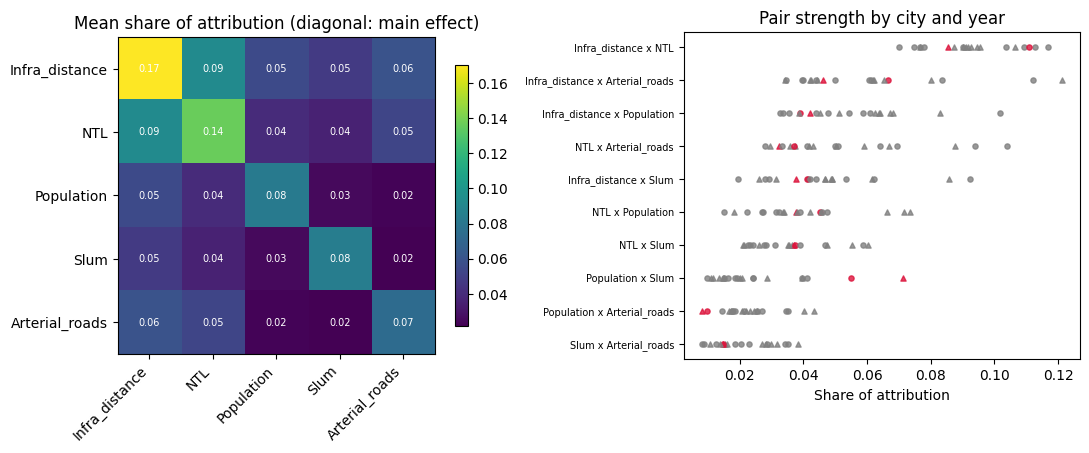

In [ ]:
"""
SHAP interaction structure of the five predictor presence model, per city and year.

One XGBoost model per city and year (same fixed hyperparameters throughout) predicts
waste presence (DV > 0) from the five predictors. XGBoost's native TreeSHAP interaction
values are averaged (absolute) over a random sample of cells, giving a 5 x 5 matrix of
main effects (diagonal) and pairwise interactions (off diagonal), scaled to sum to one
so cities are comparable. Stability is summarised by how similar this structure is
across cities and between years. Nothing is saved.
"""

import itertools
import numpy as np
import pandas as pd
import xgboost as xgb
from scipy.stats import spearmanr

COMBINED_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Combined"
JHB_PATH = "/content/drive/MyDrive/Paper_3/Miscellaneous/johannesburg_grid30m_combined_v1_popslumclean.csv"
CITIES = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
          "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]
PREDICTORS = ["Infra_distance", "NTL", "Population", "Slum", "Arterial_roads"]
YEARS = (2016, 2024)

TRAIN_MAX = 1_000_000      # cap on training rows per model (random subsample)
SAMPLE_N = 5000            # cells used to compute interaction values
PARAMS = dict(n_estimators=200, max_depth=4, learning_rate=0.1, subsample=0.8,
              colsample_bytree=1.0, min_child_weight=5, tree_method="hist",
              random_state=42, n_jobs=-1)
PLOT = True               # switch on after looking at the numbers

F = len(PREDICTORS)
pairs = list(itertools.combinations(range(F), 2))
pair_names = [f"{PREDICTORS[i]} x {PREDICTORS[j]}" for i, j in pairs]
rng = np.random.default_rng(42)

records, vectors = [], {}
for city in CITIES:
    path = JHB_PATH if city == "Johannesburg" else f"{COMBINED_DIR}/{city}/{city.lower()}_grid30m_combined.csv"
    cols = [f"{p}_{y}" for p in PREDICTORS for y in YEARS] + [f"DV_{y}" for y in YEARS]
    df = pd.read_csv(path, usecols=cols)
    for yr in YEARS:
        d = df[[f"{p}_{yr}" for p in PREDICTORS] + [f"DV_{yr}"]].copy()
        d.columns = PREDICTORS + ["DV"]
        d = d.dropna(subset=["DV"])
        y = (d["DV"] > 0).astype(int).to_numpy()
        X = d[PREDICTORS].astype("float32").reset_index(drop=True)

        order = rng.permutation(len(X))
        tr, sm = order[:TRAIN_MAX], order[:SAMPLE_N]
        model = xgb.XGBClassifier(**PARAMS).fit(X.iloc[tr], y[tr])

        inter = model.get_booster().predict(xgb.DMatrix(X.iloc[sm]), pred_interactions=True)[:, :F, :F]
        M = np.abs(inter).mean(axis=0)                  # mean |interaction| matrix
        total = M.sum()
        main = np.diag(M) / total
        pair_share = np.array([(M[i, j] + M[j, i]) / total for i, j in pairs])

        vectors[(city, yr)] = (main, pair_share)
        records.append({"city": city, "year": yr, "presence_rate": y.mean(),
                        "interaction_share": pair_share.sum(),
                        "top_pair": pair_names[int(np.argmax(pair_share))],
                        "top_pair_share": pair_share.max()})
        print(f"{city:13s} {yr} done")
    del df

res = pd.DataFrame(records)
pd.set_option("display.width", 220)
print("\n### Interaction share and strongest pair, per city and year ###")
print(res.round(3).to_string(index=False))
print(f"\nMean interaction share: {res.interaction_share.mean():.3f} "
      f"(range {res.interaction_share.min():.3f} to {res.interaction_share.max():.3f})")
print("\nStrongest pair across the 20 models:")
print(res.top_pair.value_counts().to_string())

# ---- Agreement of structure between models ----
rows = []
for a, b in itertools.combinations(vectors, 2):
    kind = ("same city, 2016 vs 2024" if a[0] == b[0] else
            "different cities, same year" if a[1] == b[1] else
            "different cities and years")
    rows.append({"kind": kind,
                 "rho_pairs_only": spearmanr(vectors[a][1], vectors[b][1]).correlation,
                 "rho_all_15": spearmanr(np.r_[vectors[a][0], vectors[a][1]],
                                         np.r_[vectors[b][0], vectors[b][1]]).correlation})
agree = pd.DataFrame(rows)
print("\n### Spearman agreement of attribution structure (pairs only = 10 values, all = 15) ###")
print(agree.groupby("kind")[["rho_pairs_only", "rho_all_15"]]
      .agg(["count", "min", "median", "max"]).round(2).to_string())

# ---- Optional figure ----
if PLOT:
    import matplotlib.pyplot as plt
    mains = np.mean([v[0] for v in vectors.values()], axis=0)
    pooled = np.mean([v[1] for v in vectors.values()], axis=0)
    H = np.zeros((F, F))
    np.fill_diagonal(H, mains)
    for k, (i, j) in enumerate(pairs):
        H[i, j] = H[j, i] = pooled[k]
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
    im = ax[0].imshow(H, cmap="viridis")
    ax[0].set_xticks(range(F)); ax[0].set_yticks(range(F))
    ax[0].set_xticklabels(PREDICTORS, rotation=45, ha="right"); ax[0].set_yticklabels(PREDICTORS)
    for i in range(F):
        for j in range(F):
            ax[0].text(j, i, f"{H[i, j]:.2f}", ha="center", va="center", color="w", fontsize=7)
    fig.colorbar(im, ax=ax[0], shrink=0.8)
    ax[0].set_title("Mean share of attribution (diagonal: main effect)")
    order = np.argsort(pooled)
    for row_i, k in enumerate(order):
        for (city, yr), (m, p) in vectors.items():
            ax[1].scatter(p[k], row_i, s=14, marker="o" if yr == 2016 else "^",
                          color="crimson" if city == "Johannesburg" else "grey", alpha=0.8)
    ax[1].set_yticks(range(len(order))); ax[1].set_yticklabels([pair_names[k] for k in order], fontsize=7)
    ax[1].set_xlabel("Share of attribution"); ax[1].set_title("Pair strength by city and year")
    plt.tight_layout(); plt.show()

In [ ]:

import os
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.ops import unary_union

# ============================================================
# 1. CONFIGURATION
# ============================================================

SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"
SHAPE_DIR = "/content/drive/MyDrive/Results_2/City_shapefiles"

CITIES = [
    "Abidjan", "Accra", "Dakar", "Freetown",
    "Johannesburg", "Kampala", "Kinshasa",
    "Lagos", "Maputo", "Nairobi"
]

YEARS = [2016, 2024]

MIN_AREA_M2 = 500
MIN_RADIUS_M = 200
MAX_RADIUS_M = 2000
CAP_PERCENTILE = 99

# Higher values give smoother circular buffers
BUFFER_RESOLUTION = 64


# ============================================================
# 2. LOAD CITY BOUNDARY
# ============================================================

def load_city_polygon(city):
    path = f"{SHAPE_DIR}/{city}_shape/{city}.shp"

    gdf = gpd.read_file(path)

    if len(gdf) > 1:
        gdf = gpd.GeoDataFrame(
            geometry=[unary_union(gdf.geometry)],
            crs=gdf.crs
        )

    return gdf


# ============================================================
# 3. LOAD QUALIFYING WASTE SITES
# ============================================================

def load_sites(city, year):
    path = (
        f"{SITES_DIR}/{year}/{city}/"
        f"{city}_{year}_sites.csv"
    )

    sites = pd.read_csv(path)

    sites = sites.dropna(
        subset=["latitude", "longitude", "area"]
    )

    sites = sites[
        sites["area"] >= MIN_AREA_M2
    ].copy()

    return sites


# ============================================================
# 4. CITY-SPECIFIC AREA CAPS
# ============================================================

def calculate_city_area_caps():
    """
    Calculate the 99th percentile of qualifying site areas
    for each city, pooling 2016 and 2024.

    The same cap is used for both years.
    """

    caps = {}

    for city in CITIES:

        areas = []

        for year in YEARS:
            sites = load_sites(city, year)
            areas.extend(sites["area"].values)

        if not areas:
            raise ValueError(
                f"No qualifying sites found for {city}"
            )

        cap = np.percentile(
            areas, CAP_PERCENTILE
        )

        caps[city] = cap

        print(
            f"{city}: {len(areas)} sites, "
            f"p{CAP_PERCENTILE} = {cap:,.1f} m²"
        )

    return caps


# ============================================================
# 5. ASSIGN VARIABLE EXPOSURE RADII
# ============================================================

def assign_site_radii(areas, area_cap):
    """
    Logarithmic scaling:

    500 m² -> 200 m radius
    City-specific p99 area -> 2000 m radius

    Areas above the cap receive the maximum radius.
    """

    areas = np.asarray(areas, dtype=float)

    if area_cap <= MIN_AREA_M2:
        return np.full(len(areas), MIN_RADIUS_M)

    capped_area = np.minimum(areas, area_cap)

    score = (
        np.log(capped_area) - np.log(MIN_AREA_M2)
    ) / (
        np.log(area_cap) - np.log(MIN_AREA_M2)
    )

    radii = (
        MIN_RADIUS_M
        + (MAX_RADIUS_M - MIN_RADIUS_M) * score
    )

    return np.clip(
        radii, MIN_RADIUS_M, MAX_RADIUS_M
    )


# ============================================================
# 6. CALCULATE EXPOSURE AREA
# ============================================================

def calculate_exposure_area(city, year, area_cap):

    city_gdf = load_city_polygon(city)
    sites = load_sites(city, year)

    if sites.empty:
        raise ValueError(
            f"No qualifying sites for {city} {year}"
        )

    # Use a projected CRS in metres
    utm_crs = city_gdf.estimate_utm_crs()

    city_projected = city_gdf.to_crs(utm_crs)
    city_geometry = unary_union(
        city_projected.geometry
    )

    # Convert waste site coordinates to projected points
    sites_gdf = gpd.GeoDataFrame(
        sites,
        geometry=gpd.points_from_xy(
            sites["longitude"],
            sites["latitude"]
        ),
        crs="EPSG:4326"
    ).to_crs(utm_crs)

    # Calculate site-specific exposure radii
    radii = assign_site_radii(
        sites["area"].values,
        area_cap
    )

    # Construct exposure buffers
    buffers = [
        point.buffer(
            float(radius),
            resolution=BUFFER_RESOLUTION
        )
        for point, radius in zip(
            sites_gdf.geometry, radii
        )
    ]

    # Merge overlapping buffers
    exposure_union = unary_union(buffers)

    # Clip to the city boundary
    exposure_clipped = exposure_union.intersection(
        city_geometry
    )

    # Calculate areas
    exposure_area_km2 = exposure_clipped.area / 1e6
    city_area_km2 = city_geometry.area / 1e6

    pct_exposed = (
        exposure_area_km2 / city_area_km2 * 100
    )

    return {
        "city": city,
        "year": year,
        "n_sites": len(sites),
        "city_area_km2": city_area_km2,
        "exposure_area_km2": exposure_area_km2,
        "pct_city_area_exposed": pct_exposed,
        "mean_radius_m": np.mean(radii),
        "median_radius_m": np.median(radii)
    }


# ============================================================
# 7. RUN ALL CITIES
# ============================================================

AREA_CAPS = calculate_city_area_caps()

results = []

for city in CITIES:

    for year in YEARS:

        try:
            result = calculate_exposure_area(
                city=city,
                year=year,
                area_cap=AREA_CAPS[city]
            )

            results.append(result)

            print(
                f"{city} {year}: "
                f"{result['exposure_area_km2']:.2f} km² "
                f"({result['pct_city_area_exposed']:.2f}%)"
            )

        except Exception as e:
            print(
                f"WARNING: {city} {year} failed: {e}"
            )

results_df = pd.DataFrame(results)


# ============================================================
# 8. CREATE CROSS-CITY SUMMARY
# ============================================================

summary_rows = []

for city in CITIES:

    sub = results_df[
        results_df["city"] == city
    ].set_index("year")

    if 2016 not in sub.index or 2024 not in sub.index:
        continue

    area_2016 = sub.loc[
        2016, "exposure_area_km2"
    ]

    area_2024 = sub.loc[
        2024, "exposure_area_km2"
    ]

    city_area = sub.loc[
        2024, "city_area_km2"
    ]

    summary_rows.append({
        "city": city,
        "city_area_km2": city_area,
        "n_sites_2016": sub.loc[2016, "n_sites"],
        "n_sites_2024": sub.loc[2024, "n_sites"],
        "exposure_area_2016_km2": area_2016,
        "exposure_area_2024_km2": area_2024,
        "change_km2": area_2024 - area_2016,
        "change_pct": (
            (area_2024 / area_2016 - 1) * 100
            if area_2016 > 0 else np.nan
        ),
        "pct_city_exposed_2016": (
            area_2016 / city_area * 100
        ),
        "pct_city_exposed_2024": (
            area_2024 / city_area * 100
        )
    })

summary_df = pd.DataFrame(
    summary_rows
).set_index("city")

print("\n" + "=" * 110)
print("EXPOSURE AREA — MAXIMUM RADIUS 2 KM")
print("Qualifying sites >= 500 m²")
print("City-specific 99th percentile area cap")
print("=" * 110)

print(summary_df.round(2).to_string())


# ============================================================
# 9. CROSS-CITY TOTALS
# ============================================================

total_2016 = summary_df[
    "exposure_area_2016_km2"
].sum()

total_2024 = summary_df[
    "exposure_area_2024_km2"
].sum()

print("\nCROSS-CITY TOTALS")
print(f"2016: {total_2016:,.2f} km²")
print(f"2024: {total_2024:,.2f} km²")
print(f"Change: {total_2024 - total_2016:+,.2f} km²")

if total_2016 > 0:
    print(
        f"Percentage change: "
        f"{(total_2024 / total_2016 - 1) * 100:+.2f}%"
    )


# ============================================================
# 10. SAVE RESULTS
# ============================================================

# OUTPUT_DIR = "/content/drive/MyDrive/Paper_3/Results"
# os.makedirs(OUTPUT_DIR, exist_ok=True)

# summary_df.to_csv(
#     f"{OUTPUT_DIR}/exposure_area_2km_summary.csv"
# )

# results_df.to_csv(
#     f"{OUTPUT_DIR}/exposure_area_2km_detailed.csv",
#     index=False
# )

print("\nResults saved successfully.")


Abidjan: 155 sites, p99 = 33,786.6 m²
Accra: 348 sites, p99 = 68,549.0 m²
Dakar: 75 sites, p99 = 71,046.5 m²
Freetown: 80 sites, p99 = 24,997.7 m²
Johannesburg: 692 sites, p99 = 66,575.5 m²
Kampala: 140 sites, p99 = 54,315.5 m²
Kinshasa: 164 sites, p99 = 5,221.3 m²
Lagos: 800 sites, p99 = 29,579.4 m²
Maputo: 85 sites, p99 = 172,163.5 m²
Nairobi: 134 sites, p99 = 178,318.1 m²
Abidjan 2016: 58.36 km² (7.48%)
Abidjan 2024: 72.60 km² (9.30%)
Accra 2016: 137.47 km² (9.34%)
Accra 2024: 213.52 km² (14.51%)
Dakar 2016: 36.26 km² (11.83%)
Dakar 2024: 25.66 km² (8.37%)
Freetown 2016: 23.29 km² (7.70%)
Freetown 2024: 48.06 km² (15.89%)
Johannesburg 2016: 137.47 km² (3.75%)
Johannesburg 2024: 355.77 km² (9.71%)
Kampala 2016: 40.61 km² (5.91%)
Kampala 2024: 60.10 km² (8.75%)
Kinshasa 2016: 82.08 km² (23.42%)
Kinshasa 2024: 117.01 km² (33.39%)
Lagos 2016: 302.63 km² (16.56%)
Lagos 2024: 443.91 km² (24.29%)
Maputo 2016: 32.90 km² (8.49%)
Maputo 2024: 48.17 km² (12.43%)
Nairobi 2016: 53.93 km² (11.85%

In [ ]:

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.mask import mask
from scipy.spatial import cKDTree
from shapely.ops import unary_union

POP_DIR = "/content/drive/MyDrive/Paper_3/Data/Population"
SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"
SHAPE_DIR = "/content/drive/MyDrive/Results_2/City_shapefiles"

ISO = dict(zip(
    ["Abidjan","Accra","Dakar","Freetown","Johannesburg","Kampala","Kinshasa","Lagos","Maputo","Nairobi"],
    ["civ","gha","sen","sle","zaf","uga","cod","nga","moz","ken"]
))
CITIES = list(ISO)
YEARS = [2016, 2024]
MIN_AREA, MIN_RADIUS, MAX_RADIUS, CAP_PCT = 500, 200, 2000, 99

def load_sites(city, year):
    path = f"{SITES_DIR}/{year}/{city}/{city}_{year}_sites.csv"
    df = pd.read_csv(path).dropna(subset=["latitude","longitude","area"])
    return df[df["area"] >= MIN_AREA].copy()

def city_boundary(city):
    gdf = gpd.read_file(f"{SHAPE_DIR}/{city}_shape/{city}.shp")
    return gdf.geometry.union_all(), gdf.crs, gdf.estimate_utm_crs()

def radii(areas, cap):
    if cap <= MIN_AREA:
        return np.full(len(areas), MIN_RADIUS, dtype=float)
    score = np.log(np.minimum(areas, cap) / MIN_AREA) / np.log(cap / MIN_AREA)
    return MIN_RADIUS + (MAX_RADIUS - MIN_RADIUS) * score

def calculate(city, year, cap):
    boundary, crs, utm = city_boundary(city)
    city_geom = gpd.GeoSeries([boundary], crs=crs).to_crs(utm).iloc[0]
    sites = load_sites(city, year)
    if sites.empty:
        raise ValueError("No qualifying sites")

    site_gdf = gpd.GeoDataFrame(
        sites, geometry=gpd.points_from_xy(sites.longitude, sites.latitude),
        crs="EPSG:4326"
    ).to_crs(utm)
    site_radii = radii(sites["area"].to_numpy(), cap)
    buffers = [p.buffer(float(r), resolution=64) for p, r in zip(site_gdf.geometry, site_radii)]
    exposure = unary_union(buffers).intersection(city_geom)

    city_area = city_geom.area / 1e6
    exposed_area = exposure.area / 1e6

    path = f"{POP_DIR}/{year}/{city}/{ISO[city]}_pop_{year}_CN_100m_R2025A_v1.tif"
    with rasterio.open(path) as src:
        city_src = gpd.GeoSeries([boundary], crs=crs).to_crs(src.crs)
        clipped, transform = mask(src, city_src, crop=True, filled=False)
        band = clipped[0]
        valid = ~np.ma.getmaskarray(band) & np.isfinite(band.data) & (band.data > 0)
        rr, cc = np.where(valid)
        pop = band.data[rr, cc].astype(float)
        xs, ys = rasterio.transform.xy(transform, rr, cc)
        pixels = gpd.GeoSeries(gpd.points_from_xy(xs, ys), crs=src.crs).to_crs(utm)

    # Population exposure follows the original pixel-centroid method
    xy = np.column_stack([pixels.x.to_numpy(), pixels.y.to_numpy()])
    site_xy = np.column_stack([site_gdf.geometry.x, site_gdf.geometry.y])
    tree = cKDTree(site_xy)
    candidates = tree.query_ball_point(xy, r=MAX_RADIUS)
    exposed = np.zeros(len(pop), dtype=bool)

    for i, ids in enumerate(candidates):
        if not ids:
            continue
        ids = np.asarray(ids)
        d = np.linalg.norm(site_xy[ids] - xy[i], axis=1)
        exposed[i] = np.any(d <= site_radii[ids])

    exposed_pop, total_pop = pop[exposed].sum(), pop.sum()
    pop_pct = 100 * exposed_pop / total_pop
    area_pct = 100 * exposed_area / city_area

    return dict(
        city=city, year=year, n_sites=len(sites),
        city_area_km2=city_area, exposure_area_km2=exposed_area,
        pct_city_area_exposed=area_pct, total_population=total_pop,
        exposed_population=exposed_pop, pct_population_exposed=pop_pct,
        concentration_index=pop_pct / area_pct if area_pct > 0 else np.nan
    )

caps = {}
for city in CITIES:
    areas = np.concatenate([load_sites(city, y)["area"].to_numpy() for y in YEARS])
    caps[city] = np.percentile(areas, CAP_PCT)

results = []
for city in CITIES:
    for year in YEARS:
        try:
            result = calculate(city, year, caps[city])
            results.append(result)
            print(f"{city} {year}: area={result['exposure_area_km2']:.2f} km², CI={result['concentration_index']:.3f}")
        except Exception as e:
            print(f"WARNING: {city} {year}: {e}")

df = pd.DataFrame(results)
cols = ["exposure_area_km2","pct_city_area_exposed","exposed_population",
        "pct_population_exposed","concentration_index"]
summary = df.pivot(index="city", columns="year", values=cols)
summary.columns = [f"{metric}_{year}" for metric, year in summary.columns]
summary["ci_change"] = summary["concentration_index_2024"] - summary["concentration_index_2016"]
summary = summary.reindex(CITIES)

print("\nEXPOSURE AREA, POPULATION AND CONCENTRATION INDEX")
print(summary.round(3).to_string())


Abidjan 2016: area=58.36 km², CI=2.119
Abidjan 2024: area=72.60 km², CI=1.500
Accra 2016: area=137.47 km², CI=1.516
Accra 2024: area=213.52 km², CI=0.908
Dakar 2016: area=36.26 km², CI=1.044
Dakar 2024: area=25.66 km², CI=0.911
Freetown 2016: area=23.29 km², CI=2.169
Freetown 2024: area=48.06 km², CI=1.883
Johannesburg 2016: area=137.47 km², CI=1.175
Johannesburg 2024: area=355.77 km², CI=0.926
Kampala 2016: area=40.61 km², CI=1.477
Kampala 2024: area=60.10 km², CI=1.293
Kinshasa 2016: area=82.08 km², CI=1.280
Kinshasa 2024: area=117.01 km², CI=1.215
Lagos 2016: area=302.63 km², CI=1.600
Lagos 2024: area=443.91 km², CI=1.449
Maputo 2016: area=32.90 km², CI=1.343
Maputo 2024: area=48.17 km², CI=1.149
Nairobi 2016: area=53.93 km², CI=1.539
Nairobi 2024: area=73.20 km², CI=1.531

EXPOSURE AREA, POPULATION AND CONCENTRATION INDEX
              exposure_area_km2_2016  exposure_area_km2_2024  pct_city_area_exposed_2016  pct_city_area_exposed_2024  exposed_population_2016  exposed_population_